# Краевые поля и хроматичность высших порядков: COSY FR 0/3 против всех моделей Bell
Решётка `magnetic_2_md` (дейтроны 270 МэВ, 16 диполей BM, секступоли выключены `k2 = 0`).
Ноутбук только **читает** готовые результаты:

* `COSY/chrom_cmp.fox` → `COSY/output/cosy_mu_series.csv` (запуск `COSY/run_cosy.bat`, ~25 мин из‑за OV 7 с FR 3);
* `BELL/run.jl` → `BELL/output/bell_models.csv`, `bell_q_series.csv` (запуск `BELL/run_bell.bat`, ~2 мин).

**GAP** — полу‑апертура (половина зазора / радиус камеры), как в COSY. Для диполя полный зазор $g = 2\,\mathrm{GAP}$,
поэтому в Bell `Enge(gap = 2GAP)`. **Краевые поля секступолей нигде не учитываются** (COSY: FR 0 для MH; Bell: `sext = NoEdge`).

## 1. Что такое каждая модель
**COSY** (`FR n` перед элементом):
* **FR 0** — жёсткий край без краевых эффектов вообще: поле — ступенька, никакой фокусировки торцом (для диполя с $e_1=e_2=0$ нет даже линейной вертикальной краевой фокусировки).
* **FR 3** — «полный» мягкий край: поле вдоль оси спадает по профилю Энге $F(z)=1/(1+e^{P(z/D)})$ с масштабом $D$ = полный зазор ($2\,\mathrm{GAP}$) для диполя / диаметр апертуры для квадруполя, и карта интегрируется численно (DA + RK) до порядка OV, включая все нелинейные (по $x,y,\delta$) члены разложения поля вне оси.

Варианты COSY: (FD, FQ) = (0,0) **FR0**; (3,0) **FR3 только диполи**; (0,3) **FR3 только квадруполи**; (3,3) **FR3 диполи+квадруполи** («всё кольцо», секступоли всё равно FR 0).
В варианте с квадрупольным FR 3 их апертура тоже равна GAP (градиент от этого не меняется: в `MQ` задано поле на полюсе $B = k\cdot AP$ при радиусе $AP$).

**Bell** (`FringeModel(dipole=…, quad=…, sext=NoEdge())`):
* **NoEdge** — то же, что COSY FR 0.
* **HardEdge(order=1)** — линейный тонкий край $p_x \mathrel{+}= h\tan\varepsilon\,x,\ p_y \mathrel{-}= h\tan\psi\,y$; при $\varepsilon=0$, FINT=0 это тождество.
* **HardEdge(order=2,3)** — нелинейный жёсткий край (вертикальный член через $\tan(\psi\pm x')$ с точным $x'=p_x/p_s$; генератор до степени 3 или 4). Это предел FR 3 при GAP→0. Для квадруполя order≥2 — кубический генератор Ли (Lee‑Whiting / Forest).
* **HardEdge(2, gap, FINT)** — тот же край с FINT профиля Энге (линейная поправка за конечный зазор).
* **SoftEdge(profile, method)** — интегрирование $s$‑зависимого гамильтониана по области $[-W,W]$ вокруг эффективной границы поля, **только для диполей** (для квадруполей в Bell мягкого края нет).
  * профили: `Enge(gap=2GAP)` (коэффициенты COSY по умолчанию), `Tanh(λ)`, `LinearRamp(w)`, `Tabulated` (Энге, затабулированный в 403…409 точках). Ширины λ, w подобраны так, что **интеграл края $I=\int F(1-F)dz$ совпадает с энговским** → одинаковый FINT, одинаковый линейный вертикальный эффект; разница между профилями — только эффект высших моментов профиля.
  * методы: `Splitting(n=40, order=4)` (произведение точных карт слоёв, Йошида), `Magnus(n=40, order=4)`, `TaylorIntegrate(tol=1e-10)` (RK4 в TaylorN, эталон).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import factorial, sqrt
pd.set_option('display.width', 200); pd.set_option('display.max_rows', 200)
M = 1875.612945; T = 270.0; g = 1 + T/M; bg = sqrt(g*g - 1)
cosy = pd.read_csv('COSY/output/cosy_mu_series.csv', skipinitialspace=True)
for c in ['FD','FQ','k']: cosy[c] = cosy[c].round().astype(int)
cosy['GAP'] = cosy['GAP'].round(6)
bell = pd.read_csv('BELL/output/bell_models.csv'); bser = pd.read_csv('BELL/output/bell_q_series.csv')
bell['gap'] = bell['gap'].round(6); bser['gap'] = bser['gap'].round(6)
print('gamma =', g, ' 1+1/gamma =', 1+1/g)

gamma = 1.1439529412077074  1+1/gamma = 1.8741618330420726


## 2. Нормировка COSY и пересчёт к $\delta = \Delta p/p$
`TP MU` при `OV NO 2 1` даёт дробные бетатронные частоты как DA‑многочлен по 5‑й переменной COSY — **относительному отклонению кинетической энергии** $\delta_K=\Delta K/K$. В файл пишется `MU|(0&0&0&0&k)` = **коэффициент Тейлора** $\mu_k$: $Q(\delta_K)=\sum_k \mu_k\delta_K^k$ (не производная, без $k!$).
Точная связь: $1+\delta_K = \dfrac{\sqrt{1+(\beta\gamma)^2(1+\delta)^2}-1}{\gamma-1}$, т.е. $\delta_K=(1+1/\gamma)\delta+\dots$ (это и есть множитель `F = 1+1/G` из старых программ). Ряд $\delta_K(\delta)$ подставляется в $Q(\delta_K)$ до порядка 6. Далее
$$Q(\delta)=\sum_n q_n\delta^n,\qquad \xi_n \equiv \frac{d^nQ}{d\delta^n}\Big|_0 = n!\,q_n .$$
В Bell `xi2` = $d^2Q/d\delta^2$ = $2q_2$ (так же определено в `chromaticity_orders`). В таблицах даны и $q_n$, и $\xi_n$.

Точность COSY: при OV 7 частота как функция $\delta_K$ получается до $\delta_K^6$, но старший коэффициент (k = 6) зависит от отброшенных членов карты порядка 8 → считаем надёжными $k\le5$.

In [2]:
N = 6
# series of dK(delta) up to delta^N by Taylor of the exact relation (numerical, high-precision polyfit on tiny grid is ill-posed -> use recurrence via numpy poly composition of sqrt)
def dK_series(N):
    # f(d) = (sqrt(1+bg^2 (1+d)^2) - 1)/(g-1) - 1 ; Taylor via sqrt(a + b d + c d^2) series
    a, b, c = 1+bg**2, 2*bg**2, bg**2
    # s(d)=sqrt(a+b d+c d^2): s^2 = P  -> s_n by recurrence
    P = [a, b, c] + [0]*N; s = [sqrt(a)] + [0]*N
    for n in range(1, N+1):
        s[n] = (P[n] - sum(s[i]*s[n-i] for i in range(1, n))) / (2*s[0])
    f = np.array(s)/(g-1); f[0] -= 1/(g-1) + 1
    return f   # f[0] = 0
fK = dK_series(N); print('dK = ', ' + '.join(f'{v:.6g} d^{i}' for i, v in enumerate(fK) if i))
def to_delta(mu):
    out = np.zeros(N+1); p = np.zeros(N+1); p[0] = 1.0
    for k in range(len(mu)):
        out += mu[k]*p
        p = np.convolve(p, fK)[:N+1]
    return out
rows = []
names = {(0,0):'FR0', (3,0):'FR3 диполи', (0,3):'FR3 квадруполи', (3,3):'FR3 диполи+квадруполи'}
for (fd, fq, gap), d in cosy.groupby(['FD','FQ','GAP']):
    d = d.sort_values('k')
    for pl, col in [('x','MUx_k'), ('y','MUy_k')]:
        q = to_delta(d[col].values)
        rows.append(dict(variant=names[(fd,fq)], FD=fd, FQ=fq, GAP=gap, plane=pl, **{f'q{n}': q[n] for n in range(N+1)},
                         **{f'mu{n}': d[col].values[n] for n in range(N+1)}))
cq = pd.DataFrame(rows)
for n in range(1, N+1): cq[f'xi{n}'] = factorial(n)*cq[f'q{n}']
cq.to_csv('cosy_q_delta.csv', index=False)
cq[cq.plane=='y'][['variant','GAP','q0','xi1','xi2','xi3','xi4','xi5']]

dK =  1.87416 d^1 + 0.716079 d^2 + -0.168881 d^3 + 0.00756609 d^4 + 0.0134335 d^5 + -0.00564444 d^6


,variant,GAP,q0,xi1,xi2,xi3,xi4,xi5
1,FR0,0.00625,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
3,FR0,0.01250,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
5,FR0,0.02500,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
7,FR0,0.05000,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
9,FR3 квадруполи,0.00625,0.461273,-2.225332,80.084668,-85.925593,4.669274e+06,4.860134e+07
11,FR3 квадруполи,0.01250,0.461090,-2.224894,78.280192,-84.613102,2.267526e+06,2.311372e+07
13,FR3 квадруполи,0.02500,0.460384,-2.223202,74.722750,-81.912221,1.079589e+06,1.057778e+07
15,FR3 квадруполи,0.05000,0.457732,-2.216842,67.752345,-76.235744,5.086117e+05,4.679150e+06
17,FR3 диполи,0.00625,0.460633,-1.815876,7.362756,-33.656781,2.001696e+02,-3.638447e+03
19,FR3 диполи,0.01250,0.459929,-1.814692,7.356074,-33.616667,1.995835e+02,-3.624527e+03


**Таблица выше** — вертикальная частота $Q_y$ и хроматичности $\xi_n=d^nQ_y/d\delta^n$ ($\delta=\Delta p/p$) для всех вариантов COSY. Для FR0 строки не зависят от GAP (апертура при FR 0 не используется) — это проверка. Ниже то же для $x$.

In [3]:
cq[cq.plane=='x'][['variant','GAP','q0','xi1','xi2','xi3','xi4','xi5']]

,variant,GAP,q0,xi1,xi2,xi3,xi4,xi5
0,FR0,0.00625,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
2,FR0,0.01250,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
4,FR0,0.02500,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
6,FR0,0.05000,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
8,FR3 квадруполи,0.00625,0.461664,-1.461380,146.014067,-141.680596,1.927042e+07,2.707636e+08
10,FR3 квадруполи,0.01250,0.461505,-1.460929,142.382155,-138.177459,9.560102e+06,1.333420e+08
12,FR3 квадруполи,0.02500,0.460888,-1.459187,135.190712,-130.913895,4.727455e+06,6.514920e+07
14,FR3 квадруполи,0.05000,0.458571,-1.452627,121.001405,-115.583133,2.350376e+06,3.197284e+07
16,FR3 диполи,0.00625,0.461720,-1.461535,8.554584,-26.879752,2.614980e+02,-4.159734e+03
18,FR3 диполи,0.01250,0.461720,-1.461533,8.554551,-26.879547,2.614951e+02,-4.159683e+03


## 3. Модели Bell: $Q$, $\xi_1$, $\xi_2$
`fringe_observables`‑эквивалент: Ли‑фактор кольца → полиномиальная карта → `chromaticity_orders` (замкнутая орбита при $\delta=0,\pm10^{-4}$, частоты из якобиана). Колонка `seconds` — время одного варианта.

In [4]:
bell[['variant','gap','width_param','Qx','Qy','xi1x','xi1y','xi2x','xi2y','seconds']]

,variant,gap,width_param,Qx,Qy,xi1x,xi1y,xi2x,xi2y,seconds
0,NoEdge,NaN,NaN,0.461720,0.461337,-1.461538,-2.225488,8.554735,8.104123,2.81
1,HardEdge1,NaN,NaN,0.461720,0.461337,-1.461538,-2.225488,8.554735,8.104123,0.66
2,HardEdge2,NaN,NaN,0.461720,0.461337,-1.461538,-1.817066,8.554735,8.186520,0.15
3,HardEdge3,NaN,NaN,0.461720,0.461337,-1.461538,-1.817065,8.554735,7.369658,0.15
4,Quad_HardEdge2,NaN,NaN,0.461720,0.461337,-1.461564,-2.225509,149.678767,81.912686,0.28
5,HardEdge2+Quad_HardEdge2,NaN,NaN,0.461720,0.461337,-1.461564,-1.817083,149.678767,81.994277,0.20
6,HardEdge2_FINT,0.05000,0.369458,0.461720,0.455693,-1.461538,-1.813213,8.554735,8.165398,0.14
7,Soft_Enge_Splitting,0.05000,0.100000,0.461720,0.455729,-1.461501,-1.807672,8.554099,7.317592,1.78
8,Soft_Enge_Magnus,0.05000,0.100000,0.461723,0.455727,-1.461508,-1.807670,8.554089,7.317570,0.67
9,Soft_Enge_TaylorIntegrate,0.05000,0.100000,0.461720,0.455729,-1.461501,-1.807673,8.554100,7.317593,3.03


## 4. Сводная таблица: COSY против Bell (линейная хроматичность)
Разности $\Delta = $ Bell − COSY для соответствующих пар: NoEdge↔FR0; SoftEdge Enge/Splitting (диполи) ↔ FR3 диполи; Soft Enge + Quad HardEdge(2) ↔ FR3 диполи+квадруполи.

In [5]:
def cpick(v, gap, pl, col='xi1'):
    r = cq[(cq.variant==v)&(cq.plane==pl)&(np.isclose(cq.GAP, gap))]; return float(r[col].iloc[0])
def bpick(v, gap, col):
    r = bell[(bell.variant==v)&((np.isclose(bell.gap, gap)) if gap==gap else bell.gap.isna())]; return float(r[col].iloc[0])
GAPS = [0.05, 0.025, 0.0125, 0.00625]; S = []
for gp in GAPS:
    for bv, cv, bg_ in [('NoEdge','FR0',np.nan), ('Soft_Enge_Splitting','FR3 диполи',gp), ('Soft_Enge_Splitting+Quad_HardEdge2','FR3 диполи+квадруполи',gp)]:
        S.append(dict(GAP=gp, Bell=bv, COSY=cv,
                      Qy_B=bpick(bv,bg_,'Qy'), Qy_C=cpick(cv,gp,'y','q0'),
                      xiy_B=bpick(bv,bg_,'xi1y'), xiy_C=cpick(cv,gp,'y'), dxiy=bpick(bv,bg_,'xi1y')-cpick(cv,gp,'y'),
                      xix_B=bpick(bv,bg_,'xi1x'), xix_C=cpick(cv,gp,'x'), dxix=bpick(bv,bg_,'xi1x')-cpick(cv,gp,'x')))
summ = pd.DataFrame(S); summ.to_csv('summary_xi1.csv', index=False); summ

,GAP,Bell,COSY,Qy_B,Qy_C,xiy_B,xiy_C,dxiy,xix_B,xix_C,dxix
0,0.05000,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002
1,0.05000,Soft_Enge_Splitting,FR3 диполи,0.455729,0.455729,-1.807672,-1.807670,-0.000002,-1.461501,-1.461498,-0.000003
2,0.05000,Soft_Enge_Splitting+Quad_HardEdge2,FR3 диполи+квадруполи,0.455729,0.452122,-1.807687,-1.796928,-0.010759,-1.461527,-1.452590,-0.008937
3,0.02500,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002
4,0.02500,Soft_Enge_Splitting,FR3 диполи,0.458525,0.458525,-1.812338,-1.812336,-0.000002,-1.461528,-1.461526,-0.000002
5,0.02500,Soft_Enge_Splitting+Quad_HardEdge2,FR3 диполи+квадруполи,0.458525,0.457571,-1.812354,-1.809500,-0.002854,-1.461555,-1.459178,-0.002377
6,0.01250,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002
7,0.01250,Soft_Enge_Splitting,FR3 диполи,0.459929,0.459929,-1.814694,-1.814692,-0.000002,-1.461535,-1.461533,-0.000002
8,0.01250,Soft_Enge_Splitting+Quad_HardEdge2,FR3 диполи+квадруполи,0.459929,0.459682,-1.814710,-1.813959,-0.000751,-1.461562,-1.460927,-0.000635
9,0.00625,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002


## 5. $\xi_y$ и $\xi_x$ в зависимости от GAP
**Рисунок 1.** Слева — вертикальная, справа — горизонтальная линейная хроматичность в зависимости от полу‑апертуры GAP. Квадраты — COSY (FR0 — серые, FR3 диполи — чёрные, FR3 квадруполи — синие, FR3 диполи+квадруполи — красные). Линии — мягкий край Bell (4 профиля × 3 метода, все с одинаковым интегралом края), пунктир — жёсткий край Bell HardEdge(2) (предел GAP→0) и HardEdge(2)+FINT. Модели, не зависящие от GAP (NoEdge, HardEdge1/2/3), показаны горизонтальными линиями. NoEdge/FR0 по $y$ ≈ −2.225 — вне масштаба, указаны в подписи.

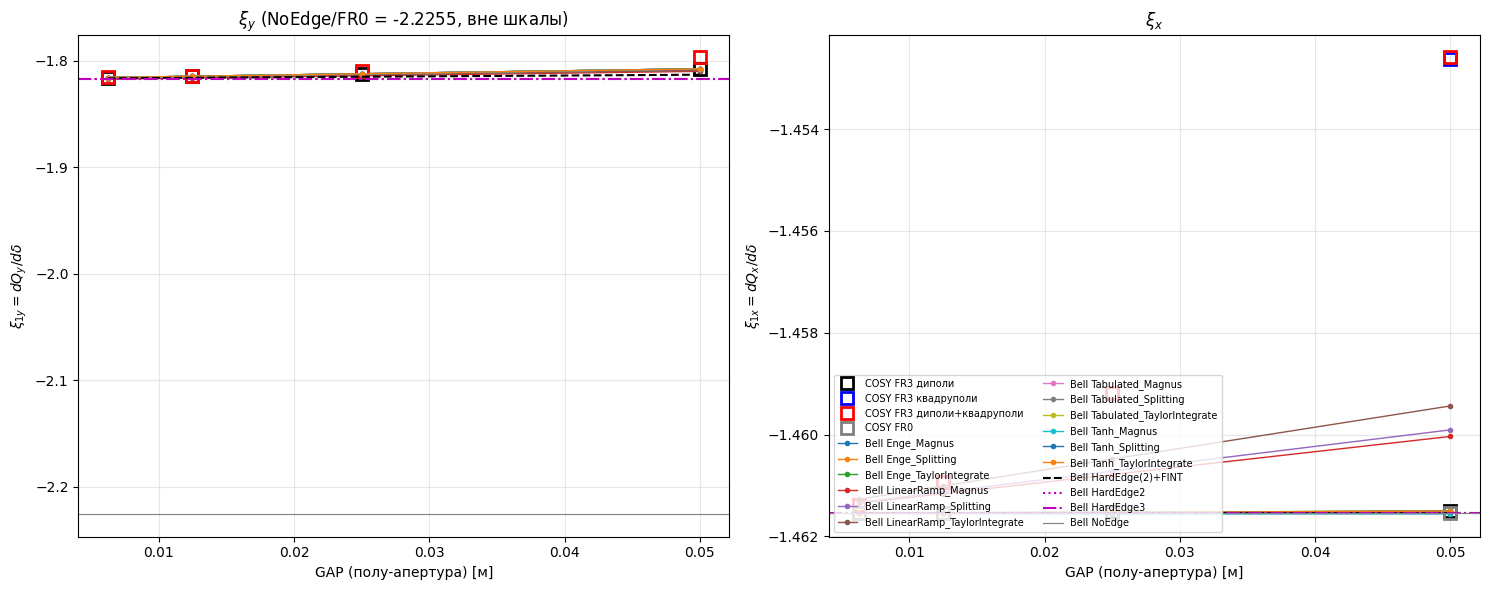

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for i, pl in enumerate(['y', 'x']):
    a = ax[i]; key = 'xi1'+pl
    for v, c in [('FR3 диполи','k'), ('FR3 квадруполи','b'), ('FR3 диполи+квадруполи','r'), ('FR0','gray')]:
        d = cq[(cq.variant==v)&(cq.plane==pl)].sort_values('GAP')
        if pl=='y' and v in ('FR0','FR3 квадруполи'): continue
        a.plot(d.GAP, d.xi1, 's', color=c, ms=9, mfc='none', mew=2, label='COSY '+v)
    soft = bell[bell.variant.str.startswith('Soft_') & ~bell.variant.str.contains('Quad')]
    for v, d in soft.groupby('variant'):
        d = d.sort_values('gap'); a.plot(d.gap, d[key], '-', marker='.', lw=1, label='Bell '+v[5:])
    d = bell[bell.variant=='HardEdge2_FINT'].sort_values('gap'); a.plot(d.gap, d[key], 'k--', label='Bell HardEdge(2)+FINT')
    for v, ls in [('HardEdge2', ':'), ('HardEdge3', '-.')]:
        a.axhline(bpick(v, np.nan, key), ls=ls, color='m', label='Bell '+v)
    a.axhline(bpick('NoEdge', np.nan, key), color='gray', lw=0.8, label='Bell NoEdge' if pl=='x' else None)
    a.set_xlabel('GAP (полу-апертура) [м]'); a.set_ylabel(r'$\xi_{1%s}=dQ_%s/d\delta$' % (pl, pl)); a.grid(alpha=.3)
ax[0].set_title(r'$\xi_y$ (NoEdge/FR0 = %.4f, вне шкалы)' % bpick('NoEdge', np.nan, 'xi1y')); ax[1].set_title(r'$\xi_x$')
ax[1].legend(fontsize=7, ncol=2, loc='lower left'); plt.tight_layout(); plt.savefig('xi_vs_gap.png', dpi=110); plt.show()

**Рисунок 2.** Разность Bell − COSY FR3 (только диполи) для $\xi_y$ (слева) и $\xi_x$ (справа) для всех мягких моделей Bell, в логарифмическом масштабе по GAP. Линейный рост с GAP означает, что расхождение — эффект конечной длины края (порядок $g/\rho$, $g^2$…), а не ошибка жёсткого предела: при GAP→0 обе программы сходятся к HardEdge(2).

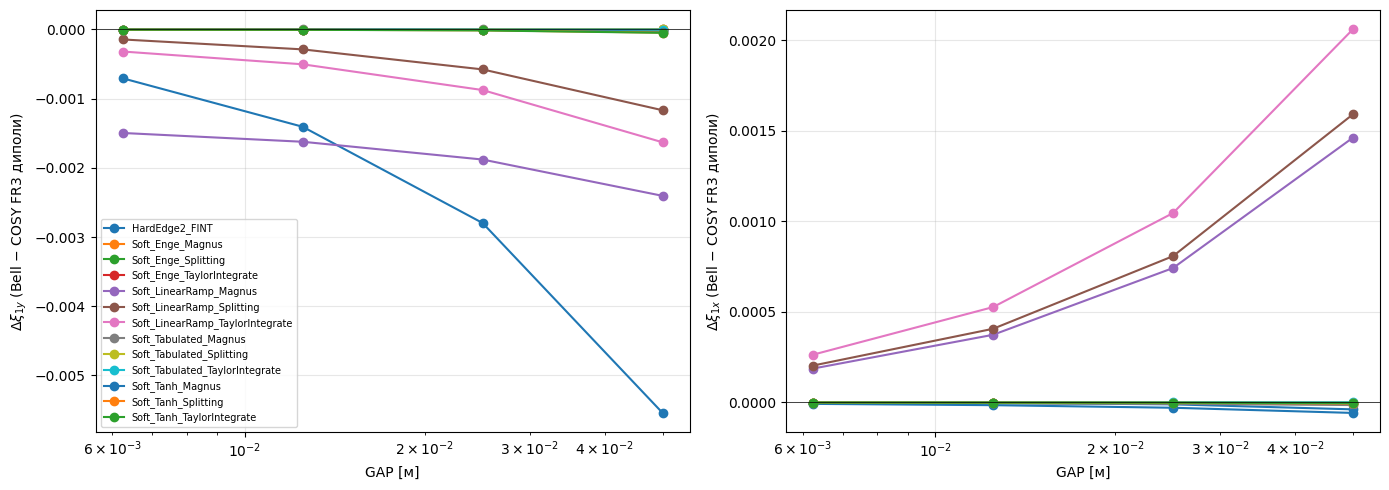

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, pl in enumerate(['y','x']):
    ref = cq[(cq.variant=='FR3 диполи')&(cq.plane==pl)].set_index('GAP')['xi1']
    for v, d in bell[bell.variant.str.startswith('Soft_') & ~bell.variant.str.contains('Quad') | (bell.variant=='HardEdge2_FINT')].groupby('variant'):
        d = d.sort_values('gap'); ax[i].plot(d.gap, d['xi1'+pl].values - ref.loc[d.gap.values].values, marker='o', label=v)
    ax[i].set_xscale('log'); ax[i].axhline(0, color='k', lw=.5); ax[i].grid(alpha=.3)
    ax[i].set_xlabel('GAP [м]'); ax[i].set_ylabel(r'$\Delta\xi_{1%s}$ (Bell − COSY FR3 диполи)' % pl)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('dxi_vs_gap.png', dpi=110); plt.show()

## 6. Вклад краевых полей квадруполей в COSY
**Рисунок 3.** Разность «FR3 только квадруполи − FR0» в COSY (сплошные) и «Bell Quad HardEdge(2) − NoEdge» (пунктир, не зависит от GAP) для $Q_x,Q_y$ (слева) и $\xi_{1x},\xi_{1y}$ (справа). Также показан вклад квадруполей поверх диполей: (FR3 диполи+квадр.) − (FR3 диполи).

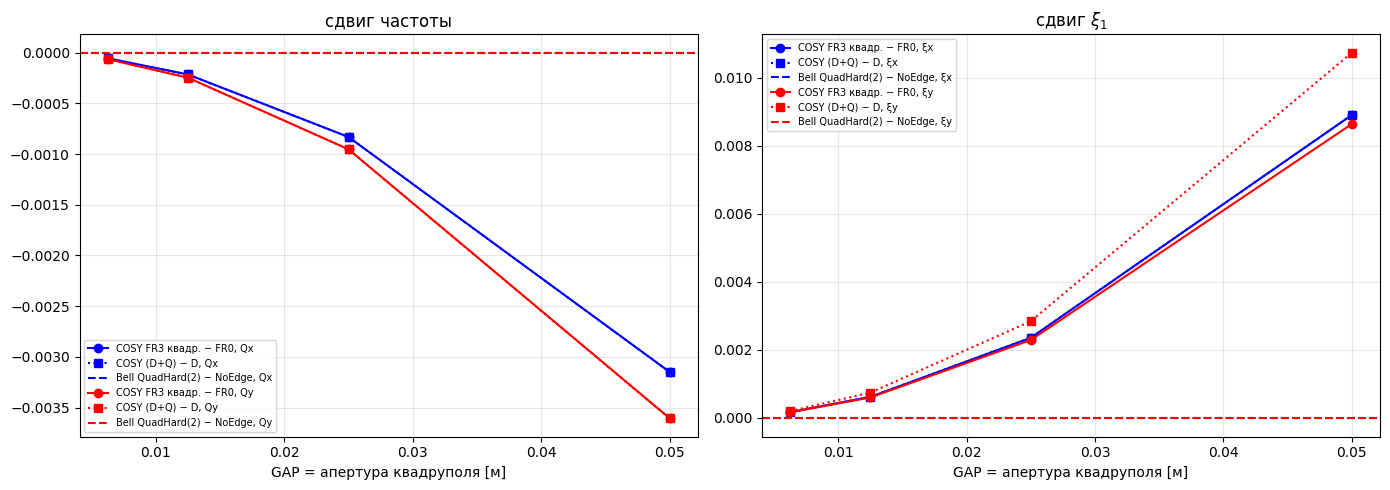

,GAP,dQx,dQy,dxi1x,dxi1y,dxi2x,dxi2y
0,0.00625,-0.000056,-0.000064,0.000156,0.000153,137.459471,71.980877
1,0.01250,-0.000216,-0.000247,0.000606,0.000591,133.827560,70.176401
2,0.02500,-0.000832,-0.000954,0.002348,0.002282,126.636117,66.618958
3,0.05000,-0.003149,-0.003605,0.008909,0.008643,112.446809,59.648554


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
def cv(v, pl, col): return cq[(cq.variant==v)&(cq.plane==pl)].sort_values('GAP')[col].values
G = np.array(sorted(GAPS))
for pl, c in [('x','b'), ('y','r')]:
    ax[0].plot(G, cv('FR3 квадруполи',pl,'q0') - cv('FR0',pl,'q0'), c+'-o', label=f'COSY FR3 квадр. − FR0, Q{pl}')
    ax[0].plot(G, cv('FR3 диполи+квадруполи',pl,'q0') - cv('FR3 диполи',pl,'q0'), c+':s', label=f'COSY (D+Q) − D, Q{pl}')
    ax[0].axhline(bpick('Quad_HardEdge2',np.nan,'Q'+pl) - bpick('NoEdge',np.nan,'Q'+pl), color=c, ls='--', label=f'Bell QuadHard(2) − NoEdge, Q{pl}')
    ax[1].plot(G, cv('FR3 квадруполи',pl,'xi1') - cv('FR0',pl,'xi1'), c+'-o', label=f'COSY FR3 квадр. − FR0, ξ{pl}')
    ax[1].plot(G, cv('FR3 диполи+квадруполи',pl,'xi1') - cv('FR3 диполи',pl,'xi1'), c+':s', label=f'COSY (D+Q) − D, ξ{pl}')
    ax[1].axhline(bpick('Quad_HardEdge2',np.nan,'xi1'+pl) - bpick('NoEdge',np.nan,'xi1'+pl), color=c, ls='--', label=f'Bell QuadHard(2) − NoEdge, ξ{pl}')
for a, t in zip(ax, ['сдвиг частоты', r'сдвиг $\xi_1$']):
    a.set_title(t); a.set_xlabel('GAP = апертура квадруполя [м]'); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig('quad_contribution.png', dpi=110); plt.show()
qc = pd.DataFrame({'GAP': G,
   'dQx': cv('FR3 квадруполи','x','q0')-cv('FR0','x','q0'), 'dQy': cv('FR3 квадруполи','y','q0')-cv('FR0','y','q0'),
   'dxi1x': cv('FR3 квадруполи','x','xi1')-cv('FR0','x','xi1'), 'dxi1y': cv('FR3 квадруполи','y','xi1')-cv('FR0','y','xi1'),
   'dxi2x': cv('FR3 квадруполи','x','xi2')-cv('FR0','x','xi2'), 'dxi2y': cv('FR3 квадруполи','y','xi2')-cv('FR0','y','xi2')}); qc

**Таблица** — вклад квадрупольных краёв в COSY (FR3 квадр. − FR0). Сдвиги частот и $\xi_1$ растут как $\mathrm{GAP}^2$ (каждое удвоение апертуры ×4): при 5 см $\Delta Q_x=-3.1\cdot10^{-3}$, $\Delta Q_y=-3.6\cdot10^{-3}$, $\Delta\xi_{1x}\approx\Delta\xi_{1y}\approx+8.8\cdot10^{-3}$; при 6.25 мм — $\sim10^{-4}$. Это эффект конечной длины мягкого края квадруполя ($\propto k\,a^2$). Жёсткий кубический край Bell даёт в пределе ноль для $Q$ и $\sim3\cdot10^{-5}$ для $\xi_1$ — согласуется с пределом COSY GAP→0.
Зато во **второй хроматичности** квадрупольный край — главный эффект: $\xi_{2x}$ 8.55 → 121…146, $\xi_{2y}$ 8.10 → 68…80 (COSY), а Bell Quad HardEdge(2) даёт 149.7 / 81.9 — это и есть предел COSY при GAP→0 (члены $\propto x^3p_x,\ xy^2p_x$ на дисперсионной орбите дают $\delta^2$ в частоте).

## 7. Хроматичность высших порядков
Bell: карта кольца точна до **3‑го порядка** по $(x,p_x,y,p_y,l,\delta)$ (`JET_ORDER = 4`, `MAP_ORDER = 3` — константы в `lie_algebra.jl`). Якобиан на замкнутой орбите точен до $\delta^2$ ⇒ надёжны только $Q_0,\xi_1,\xi_2$. В `bell_q_series.csv` записан полиномиальный фит $Q(\delta)$ по 17 точкам $|\delta|\le4\cdot10^{-3}$ до $\delta^4$; коэффициенты $q_3,q_4$ помечены `reliable = 0` — это артефакты обрезки карты.
COSY: OV 7, надёжны $\xi_1\dots\xi_5$.

**Таблица** — $\xi_n = n!\,q_n$ (по $\delta=\Delta p/p$): COSY FR0 vs Bell NoEdge, COSY FR3 диполи vs Bell Soft Enge Splitting при GAP = 0.05 и 0.00625 м.

In [9]:
def bq(v, gap):
    d = bser[(bser.variant==v)&((np.isclose(bser.gap,gap)) if gap==gap else bser.gap.isna())].sort_values('k'); return d
H = []
for gp, cvn, bv, bgp in [(0.05,'FR0','NoEdge',np.nan), (0.05,'FR3 диполи','Soft_Enge_Splitting',0.05), (0.00625,'FR3 диполи','Soft_Enge_Splitting',0.00625),
                          (0.05,'FR3 диполи+квадруполи','Soft_Enge_Splitting+Quad_HardEdge2',0.05)]:
    for pl in ['x','y']:
        r = cq[(cq.variant==cvn)&(cq.plane==pl)&np.isclose(cq.GAP,gp)].iloc[0]; b = bq(bv,bgp)
        H.append(dict(GAP=gp, model=f'COSY {cvn}', plane=pl, **{f'xi{n}': r[f'xi{n}'] for n in range(1,6)}))
        bb = {f'xi{n}': factorial(n)*b[f'q{pl}_k'].values[n] for n in range(1,5)}
        bb['xi1'] = bpick(bv,bgp,'xi1'+pl); bb['xi2'] = bpick(bv,bgp,'xi2'+pl)
        H.append(dict(GAP=gp, model=f'Bell {bv}', plane=pl, **bb, xi5=np.nan))
hi = pd.DataFrame(H); hi.to_csv('higher_order_table.csv', index=False); hi

,GAP,model,plane,xi1,xi2,xi3,xi4,xi5
0,0.05000,COSY FR0,x,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
1,0.05000,Bell NoEdge,x,-1.461538,8.554735,-1116.441094,1.746635e+05,NaN
2,0.05000,COSY FR0,y,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
3,0.05000,Bell NoEdge,y,-2.225488,8.104123,-1929.902539,4.342999e+05,NaN
4,0.05000,COSY FR3 диполи,x,-1.461498,8.553898,-26.875475,2.614394e+02,-4.158673e+03
5,0.05000,Bell Soft_Enge_Splitting,x,-1.461501,8.554099,-1116.340148,1.746443e+05,NaN
6,0.05000,COSY FR3 диполи,y,-1.807670,7.316550,-33.382915,1.962324e+02,-3.545161e+03
7,0.05000,Bell Soft_Enge_Splitting,y,-1.807672,7.317592,-1143.299317,1.839876e+05,NaN
8,0.00625,COSY FR3 диполи,x,-1.461535,8.554584,-26.879752,2.614980e+02,-4.159734e+03
9,0.00625,Bell Soft_Enge_Splitting,x,-1.461537,8.554725,-1116.439535,1.746632e+05,NaN


**Рисунок 4.** Модули $|\xi_n|$ ($n=1..5$, лог. шкала) для $x$ (слева) и $y$ (справа). Сплошные — COSY (FR0, FR3 диполи, FR3 квадруполи, FR3 D+Q при GAP = 5 см), маркеры‑звёзды — Bell NoEdge и Soft Enge (GAP 5 см): закрашенные — надёжные ($n\le2$), пустые — артефакты карты 3‑го порядка ($n=3,4$). Видно: (а) для $n\le2$ Bell совпадает с COSY FR0/FR3‑диполи; (б) квадрупольный FR 3 в COSY резко увеличивает $\xi_2$ и особенно $\xi_4$ — это вклад членов поля $\propto k'' (x^2+y^2)$ вне оси, растущий при уменьшении апертуры (см. рис. 5).

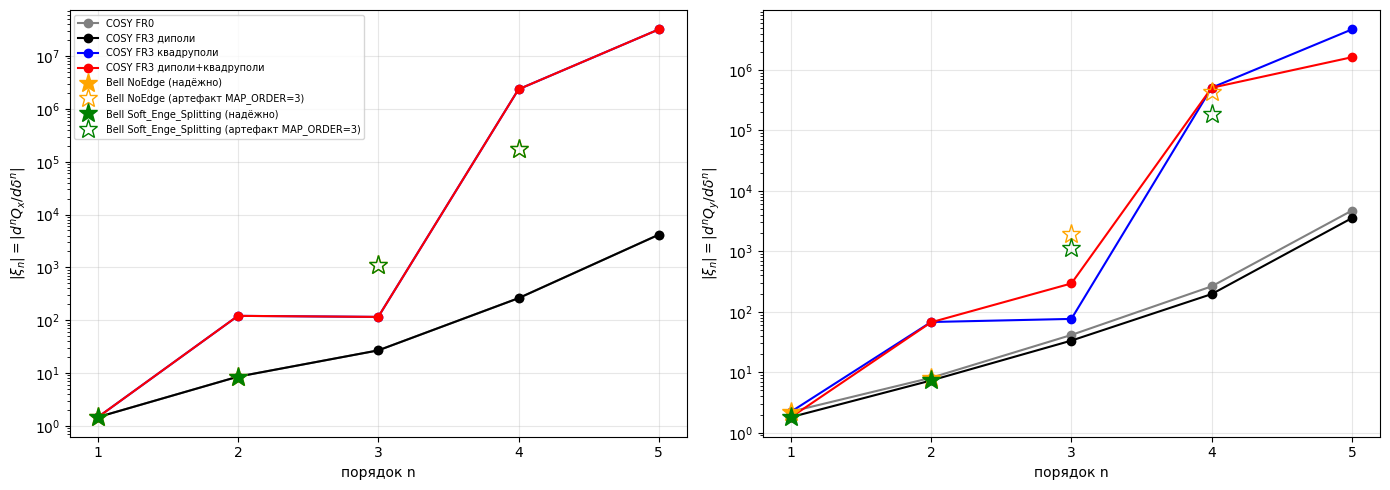

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5)); n = np.arange(1, 6)
for i, pl in enumerate(['x','y']):
    for v, c in [('FR0','gray'), ('FR3 диполи','k'), ('FR3 квадруполи','b'), ('FR3 диполи+квадруполи','r')]:
        r = cq[(cq.variant==v)&(cq.plane==pl)&np.isclose(cq.GAP,0.05)].iloc[0]
        ax[i].semilogy(n, [abs(r[f'xi{k}']) for k in n], '-o', color=c, label='COSY '+v)
    for bv, bgp, c in [('NoEdge', np.nan, 'orange'), ('Soft_Enge_Splitting', 0.05, 'green')]:
        b = bq(bv, bgp); xs = [abs(bpick(bv,bgp,'xi1'+pl)), abs(bpick(bv,bgp,'xi2'+pl))] + [abs(factorial(k)*b[f'q{pl}_k'].values[k]) for k in (3,4)]
        ax[i].semilogy([1,2], xs[:2], '*', ms=14, color=c, label='Bell '+bv+' (надёжно)')
        ax[i].semilogy([3,4], xs[2:], '*', ms=14, mfc='none', color=c, label='Bell '+bv+' (артефакт MAP_ORDER=3)')
    ax[i].set_xlabel('порядок n'); ax[i].set_ylabel(r'$|\xi_n| = |d^nQ_%s/d\delta^n|$' % pl); ax[i].grid(alpha=.3); ax[i].set_xticks(n)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('higher_order.png', dpi=110); plt.show()

**Рисунок 5.** $\xi_2$ и $\xi_3$ в зависимости от GAP для всех вариантов COSY (лево: $x$, право: $y$) и $\xi_2$ Bell (звёзды — Soft Enge Splitting, линии — NoEdge/HardEdge2). Квадрупольный FR 3 даёт большую $\xi_2$, которая при GAP→0 стремится к жёсткому пределу Bell Quad HardEdge(2) (голубая/красная штриховая). Для диполей: HardEdge(2) даёт $\xi_{2y}=8.19$, а HardEdge(3) — 7.37, что и есть предел COSY FR3 (7.363 при 6.25 мм): для $\xi_2$ нужен край 3‑го порядка.

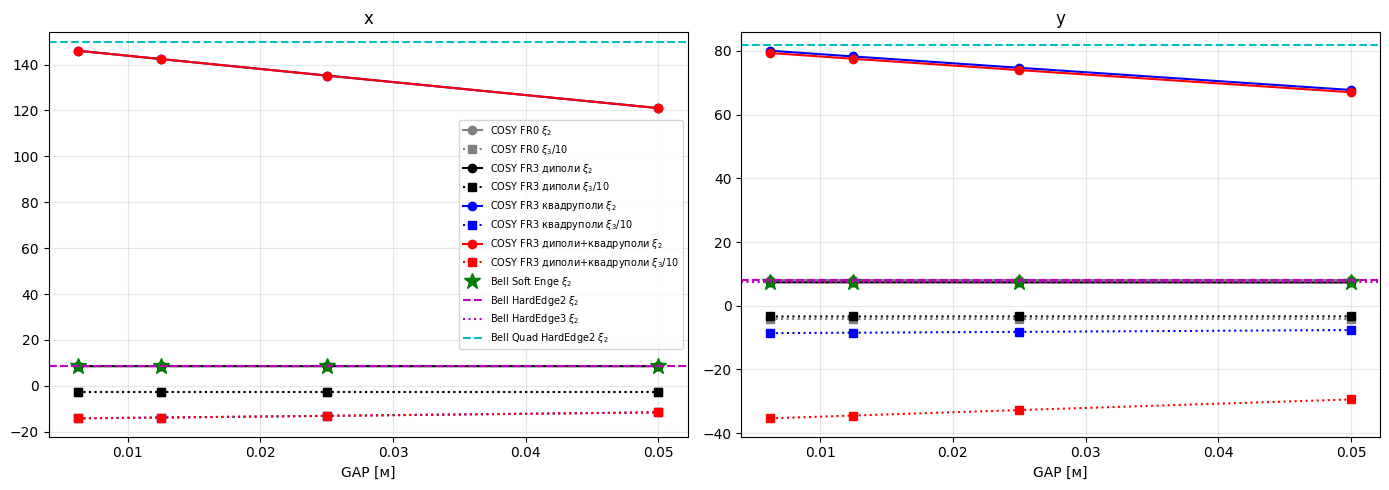

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, pl in enumerate(['x','y']):
    for v, c in [('FR0','gray'), ('FR3 диполи','k'), ('FR3 квадруполи','b'), ('FR3 диполи+квадруполи','r')]:
        d = cq[(cq.variant==v)&(cq.plane==pl)].sort_values('GAP')
        ax[i].plot(d.GAP, d.xi2, '-o', color=c, label='COSY '+v+r' $\xi_2$'); ax[i].plot(d.GAP, d.xi3/10, ':s', color=c, label='COSY '+v+r' $\xi_3/10$')
    d = bell[bell.variant=='Soft_Enge_Splitting'].sort_values('gap'); ax[i].plot(d.gap, d['xi2'+pl], 'g*', ms=12, label=r'Bell Soft Enge $\xi_2$')
    ax[i].axhline(bpick('HardEdge2',np.nan,'xi2'+pl), color='m', ls='--', label=r'Bell HardEdge2 $\xi_2$')
    ax[i].axhline(bpick('HardEdge3',np.nan,'xi2'+pl), color='m', ls=':', label=r'Bell HardEdge3 $\xi_2$')
    ax[i].axhline(bpick('Quad_HardEdge2',np.nan,'xi2'+pl), color='c', ls='--', label=r'Bell Quad HardEdge2 $\xi_2$')
    ax[i].set_xlabel('GAP [м]'); ax[i].set_title(pl); ax[i].grid(alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('xi2_vs_gap.png', dpi=110); plt.show()

**Рисунок 6.** Сами кривые $Q(\delta)-Q_0$ на $|\delta|\le 5\cdot10^{-3}$: ряд COSY FR3 диполи (до $\delta^5$), обрезанный до $\delta^2$, и ряд Bell Soft Enge до $\delta^2$ (GAP 5 см). Нижние панели — разности; видно, какой вклад в $Q(\delta)$ дают члены $\delta^{\ge3}$ (их Bell пока не даёт).

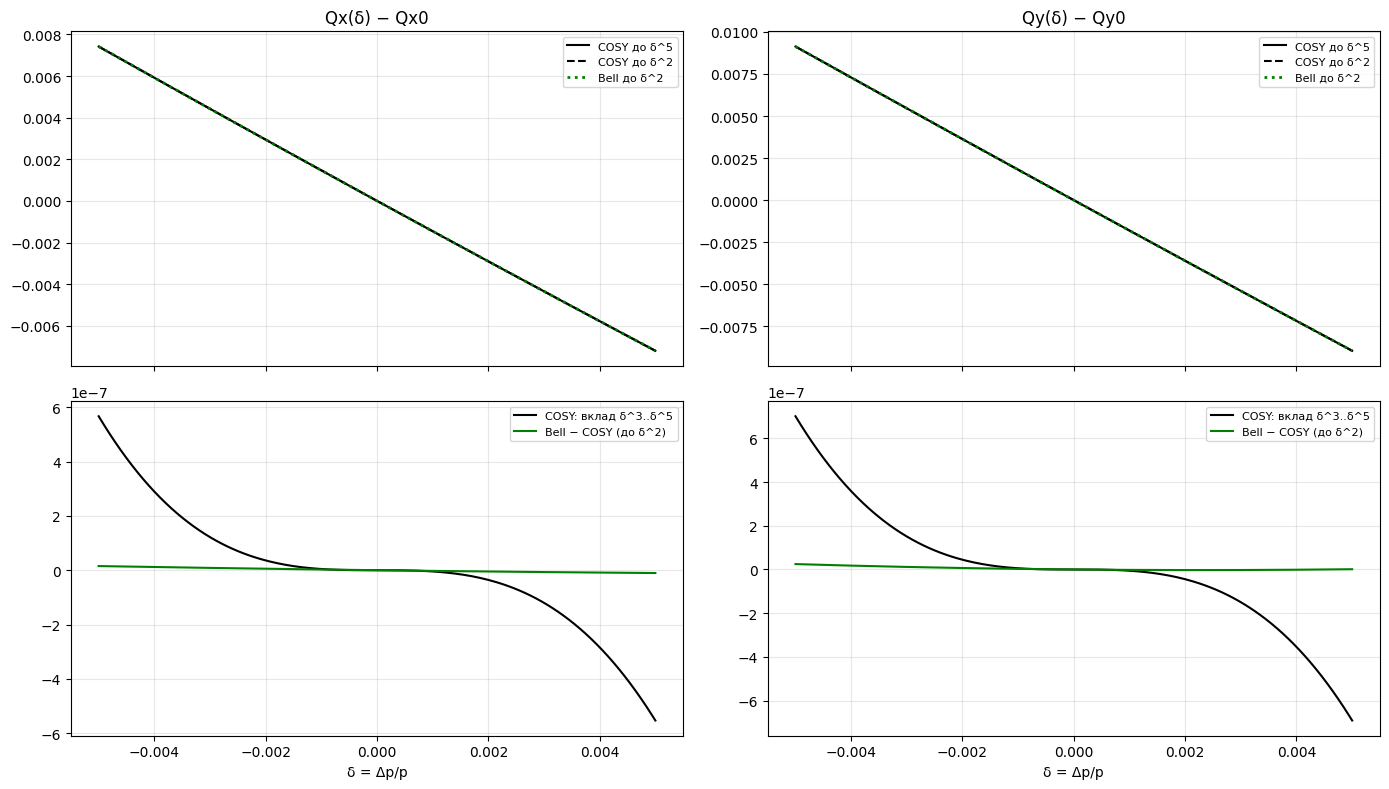

In [12]:
dd = np.linspace(-5e-3, 5e-3, 201); fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for i, pl in enumerate(['x','y']):
    r = cq[(cq.variant=='FR3 диполи')&(cq.plane==pl)&np.isclose(cq.GAP,0.05)].iloc[0]
    Qc5 = sum(r[f'q{k}']*dd**k for k in range(1,6)); Qc2 = sum(r[f'q{k}']*dd**k for k in range(1,3))
    Qb = bpick('Soft_Enge_Splitting',0.05,'xi1'+pl)*dd + bpick('Soft_Enge_Splitting',0.05,'xi2'+pl)/2*dd**2
    ax[0,i].plot(dd, Qc5, 'k', label='COSY до δ^5'); ax[0,i].plot(dd, Qc2, 'k--', label='COSY до δ^2'); ax[0,i].plot(dd, Qb, 'g:', lw=2, label='Bell до δ^2')
    ax[1,i].plot(dd, Qc5-Qc2, 'k', label='COSY: вклад δ^3..δ^5'); ax[1,i].plot(dd, Qb-Qc2, 'g', label='Bell − COSY (до δ^2)')
    ax[0,i].set_title(f'Q{pl}(δ) − Q{pl}0'); ax[1,i].set_xlabel('δ = Δp/p'); [a.grid(alpha=.3) or a.legend(fontsize=8) for a in ax[:,i]]
plt.tight_layout(); plt.savefig('q_of_delta.png', dpi=110); plt.show()

## 8. Откуда расхождение: диполи или квадруполи
Выводы ниже вычисляются по данным (ячейка печатает числа), текст — интерпретация.

In [13]:
s = summ
print('xi1 Bell NoEdge - COSY FR0:          dx = %.1e  dy = %.1e' % tuple(s[s.COSY=='FR0'][['dxix','dxiy']].iloc[0]))
for gp in GAPS:
    r = s[(s.COSY=='FR3 диполи')&np.isclose(s.GAP,gp)].iloc[0]
    print(f'GAP {gp:<8} Bell SoftEnge - COSY FR3 dip:  dxi_x = {r.dxix:+.2e}  dxi_y = {r.dxiy:+.2e}')
print(); print(qc.to_string(index=False))

xi1 Bell NoEdge - COSY FR0:          dx = -1.8e-06  dy = -3.0e-06
GAP 0.05     Bell SoftEnge - COSY FR3 dip:  dxi_x = -2.56e-06  dxi_y = -2.35e-06
GAP 0.025    Bell SoftEnge - COSY FR3 dip:  dxi_x = -2.23e-06  dxi_y = -2.21e-06
GAP 0.0125   Bell SoftEnge - COSY FR3 dip:  dxi_x = -2.03e-06  dxi_y = -2.16e-06
GAP 0.00625  Bell SoftEnge - COSY FR3 dip:  dxi_x = -1.93e-06  dxi_y = -2.13e-06

    GAP       dQx       dQy    dxi1x    dxi1y      dxi2x     dxi2y
0.00625 -0.000056 -0.000064 0.000156 0.000153 137.459471 71.980877
0.01250 -0.000216 -0.000247 0.000606 0.000591 133.827560 70.176401
0.02500 -0.000832 -0.000954 0.002348 0.002282 126.636117 66.618958
0.05000 -0.003149 -0.003605 0.008909 0.008643 112.446809 59.648554


**Анализ.**
1. **Жёсткий предел совпадает.** Bell NoEdge = COSY FR0 ($|\Delta\xi_1|\le3\cdot10^{-6}$, $\xi_2$ до $4\cdot10^{-4}$). Bell HardEdge(2/3) по $\xi_{1y}$ = −1.81707 = экстраполяция COSY FR3 (диполи) к GAP→0. HardEdge(1) при $\varepsilon=0$, FINT=0 — тождество (= NoEdge).
2. **(До исправления Bell, разд. 9–10.) Расхождение по $\xi_1$ — диполи.** В варианте «FR3 только диполи» Bell Soft Enge − COSY: $\Delta\xi_{1y}=+1.0\cdot10^{-3}$, $\Delta\xi_{1x}=-2.9\cdot10^{-3}$ при 5 см, строго $\propto$GAP (половина на каждом шаге). Все 3 метода Bell для гладких профилей (Enge, Tanh, Tabulated) согласуются между собой до $\sim10^{-5}$–$10^{-4}$ — это не ошибка интегратора, а разная постановка мягкого края диполя (как распределены кривизна опорной орбиты/длина пути в краю относительно EFB; в $x$ это член $\propto h\,g$). $Q_y$ при этом совпадает до $10^{-6}$ — линейная вертикальная фокусировка края (FINT) у обеих программ одинакова. LinearRamp+Magnus(40) заметно хуже (разрыв $F'$ трапеции).
3. **Квадруполи в COSY вносят материальный вклад:** $\Delta Q\approx-3\cdot10^{-3}$ и $\Delta\xi_1\approx+9\cdot10^{-3}$ при 5 см ($\propto\mathrm{GAP}^2$) — **больше**, чем дипольное расхождение; в Bell мягкого края квадруполя нет, поэтому для «всего кольца» разность Bell−COSY по $\xi_{1x}$ = −1.2·10⁻² при 5 см. При GAP ≤ 1 см эффект ≤ 6·10⁻⁴.
4. **$\xi_2$:** доминирует жёсткий кубический край квадруполей (×15 по $x$, ×10 по $y$), и Bell (Quad HardEdge(2)) воспроизводит предел COSY. Для диполей Bell Soft Enge vs COSY: $\Delta\xi_{2y}=+1\cdot10^{-2}$ (5 см) → $+1.4\cdot10^{-3}$ (6.25 мм); дипольный HardEdge(2) даёт неверную $\xi_{2y}$ (8.19 вместо 7.37), нужен HardEdge(3).
5. **$\xi_{\ge3}$:** Bell в текущем публичном API не даёт (карта 3‑го порядка: фит даёт $\xi_3\sim-1100$ вместо −27 у COSY — артефакт). У COSY с квадрупольным FR 3 $\xi_4,\xi_5\sim10^6$–$10^8$ и растут как 1/GAP (плюс предупреждения RK «minimum stepsize»): высшие порядки там определяются производными профиля Энге и сильно модельно‑зависимы; без квадрупольного края ряд COSY регулярен ($\xi_3\approx-27/-33$, $\xi_4\approx260/200$, $\xi_5\approx-4\cdot10^3$).

## 9. Откуда дипольное расхождение: эксперименты с одиночным диполем (Bell **до** исправления)
Все таблицы и рисунки этого раздела построены по сохранённым результатам Bell до исправления (`*/output_before_fix/`). Разделы 3–8 выше пересчитаны уже **после** исправления (см. раздел 10).
Программы в `single_dipole/` (порядок запуска: `cosy single_bm.fox`, `julia --project=../BELL single_bm.jl`, `ring_bm_optics.jl`, `b2_strength.jl`, затем `python compare_single.py`, `perturb_xi.py`, `b2_estimate.py`):
* `single_bm.fox` — один BM (FR 0 и FR 3 при GAP 0.05/0.025/0.0125), `OV 3 2 1`, карта печатается `PM`: (а) дрейф 0.5 м + BM + дрейф 0.5 м, (б) «голый» BM, как в кольце (BM вплотную к квадруполям).
* `single_bm.jl` / `ring_bm_optics.jl` — те же карты в Bell (NoEdge, HardEdge3, SoftEdge Enge(2GAP) + TaylorIntegrate) и для каждого из 16 BM кольца — линейная матрица оборота на его входе и вектор дисперсии $D_1$ (кольцо с мягкими краями Bell).
* Карты COSY пересчитаны из $\delta_K$ в $\delta=\Delta p/p$ (точная подстановка ряда до 3‑го порядка), координаты $a=p_x/p_0$, $b=p_y/p_0$ совпадают с $p_x,p_y$ Bell.

### 9.1. Поэлементное сравнение карты (дрейф + BM + дрейф)
**Таблица.** Коэффициенты, где Bell Soft − COSY FR3 > $10^{-7}$ (GAP 5 см), рядом разность при 2.5 см и их отношение $r$. Обозначение $(p_x|xa)$ = коэффициент при $x\,a$ в $p_x$.

In [14]:
sd = pd.read_csv('single_dipole/output_before_fix/single_bm_compare.csv')
sd['d_noedge'] = sd.bell_NoEdge - sd.cosy_FR0; sd['r'] = sd['diff_0.05']/sd['diff_0.025'].replace(0, np.nan)
show = sd[(sd['diff_0.05'].abs() > 1e-7) | (sd.d_noedge.abs() > 1e-7)]
show[['term','order','cosy_FR0','d_noedge','cosy_FR3_0.05','bell_Soft_0.05','diff_0.05','diff_0.025','r']].reset_index(drop=True)

,term,order,cosy_FR0,d_noedge,cosy_FR3_0.05,bell_Soft_0.05,diff_0.05,diff_0.025,r
0,(x|d),1,1.224391e+00,3.488305e-08,1.224376e+00,1.224376,-4.176927e-07,-2.370839e-07,1.761792
1,(x|a),1,6.110320e+00,-2.698958e-09,6.110321e+00,6.110321,-3.083692e-07,8.310300e-08,-3.710687
2,(px|d),1,3.826834e-01,8.534110e-09,3.826787e-01,0.382679,-1.197587e-07,-7.063579e-08,1.695440
3,(y|b),1,6.329415e+00,-2.000000e-07,6.330671e+00,6.330671,1.111516e-07,3.728233e-07,0.298135
4,(y|y),1,1.000000e+00,0.000000e+00,1.001270e+00,1.001270,-2.111442e-07,-1.368309e-07,1.543103
5,(py|b),1,1.000000e+00,0.000000e+00,1.001270e+00,1.001270,-2.111442e-07,-1.368309e-07,1.543103
6,(x|d^2),2,-1.185073e+00,-1.087746e-07,-1.184994e+00,-1.184987,6.054089e-06,2.986793e-06,2.026953
7,(x|b^2),2,-6.121956e-01,5.754673e-08,-1.856238e+00,-1.856340,-1.017481e-04,-4.870409e-05,2.089108
8,(x|yb),2,0.000000e+00,0.000000e+00,-3.967819e-01,-0.396846,-6.394133e-05,-3.079658e-05,2.076248
9,(x|y^2),2,0.000000e+00,0.000000e+00,-3.402834e-03,-0.003434,-3.134437e-05,-1.594425e-05,1.965873


**Что видно.**
* **Линейная матрица** (порядок 1) совпадает до $\sim10^{-7}$, в т.ч. $(y|y)=(p_y|p_y)=1.001270$ (вертикальная фокусировка края), $(x|\delta)$, $(p_x|\delta)$. Значит, масштаб Энге (полный зазор $2\,$GAP), коэффициенты Энге (у Bell `ENGE_DEFAULT` = коэффициенты COSY по умолчанию из руководства), положение эффективной границы (равные площади, спад «оседлывает» край) и угол $e_1=e_2=0$ трактуются одинаково. Отсюда совпадение $Q_y$ кольца до $10^{-6}$.
* **Хроматические члены** $(x|x\delta)$, $(p_x|x\delta)$, $(y|y\delta)$, $(p_y|y\delta)$, $(y|b\delta)$, … отличаются лишь на $10^{-5}$.
* **Геометрические члены 2‑го порядка** отличаются на $10^{-5}$–$10^{-4}$, и отличие **строго ∝ GAP** ($r\approx2$): у COSY FR3 горизонтальные $(p_x|x^2)$, $(p_x|xa)$, $(p_x|x\delta)$ остаются **нулевыми** ($\le10^{-9}$, как при FR0), а у Bell они $\approx 2\cdot10^{-5}$, $1.2\cdot10^{-4}$, $2\cdot10^{-5}$. В вертикали $(p_y|xy)$, $(y|xy)$, $(p_y|xb)$ у Bell больше по модулю.
* Члены 3‑го порядка в $y$ (например $(y|b^3)$, $(p_y|y^3)$) отличаются сильно и с $r\approx0.5$ (∝ 1/GAP) — это октупольноподобные члены края, которые от $\delta$ не зависят и на линейную хроматичность не влияют.

### 9.2. Какие члены карты дают $\Delta\xi$ кольца
Возмущение первого порядка: на замкнутой орбите $z(\delta)=(D_1\delta,\,\delta)$ производная якобиана элемента $J'_{ij}=\sum_k \partial^2 M_i/\partial z_j\partial z_k\, w_k$, $w=(D,D',0,0,1)$; изменение следа матрицы оборота $\Delta\,\mathrm{tr} = \mathrm{tr}(R_{\rm rest}\,\Delta J')$, $R_{\rm rest}=M_{\rm оборот}R_{BM}^{-1}$; $\Delta\xi = -\Delta\mathrm{tr}/(4\pi\sin2\pi Q)$, сумма по 16 BM. Это разложение даёт вклад каждого коэффициента $(i|z_jz_k)$ голого BM.

**Таблица.** Сумма по членам (`dxi_*_pert`) для трёх пар; для сравнения в кольце: Bell Soft − COSY FR3 = −2.888·10⁻³ / +1.007·10⁻³ (5 см).

In [15]:
ps = pd.read_csv('single_dipole/output_before_fix/perturb_summary.csv'); ps

,gap,pair,dxi_x_pert,dxi_y_pert
0,0.0500,BellSoft-COSYFR3,-0.002885,0.001009
1,0.0500,BellSoft-BellNoEdge,-0.002832,0.409748
2,0.0500,COSYFR3-COSYFR0,0.000054,0.408739
3,0.0250,BellSoft-COSYFR3,-0.001452,0.000505
4,0.0250,BellSoft-BellNoEdge,-0.001439,0.408871
5,0.0250,COSYFR3-COSYFR0,0.000013,0.408367
6,0.0125,BellSoft-COSYFR3,-0.000728,0.000253
7,0.0125,BellSoft-BellNoEdge,-0.000725,0.408587
8,0.0125,COSYFR3-COSYFR0,0.000004,0.408335


Формула воспроизводит прямой расчёт кольца с точностью ~1 % (−2.885·10⁻³ / +1.009·10⁻³ против −2.888·10⁻³ / +1.007·10⁻³), т.е. весь эффект — в коэффициентах 2‑го порядка карты диполя. Заметьте: **у COSY мягкий край почти не меняет $\xi_x$** (FR3 − FR0 = +5·10⁻⁵), а у Bell меняет на −2.8·10⁻³.

**Рисунок 7.** Вклады отдельных коэффициентов голого BM в $\Delta\xi_x$ (слева) и $\Delta\xi_y$ (справа) для разности Bell Soft − COSY FR3, GAP = 5 см.

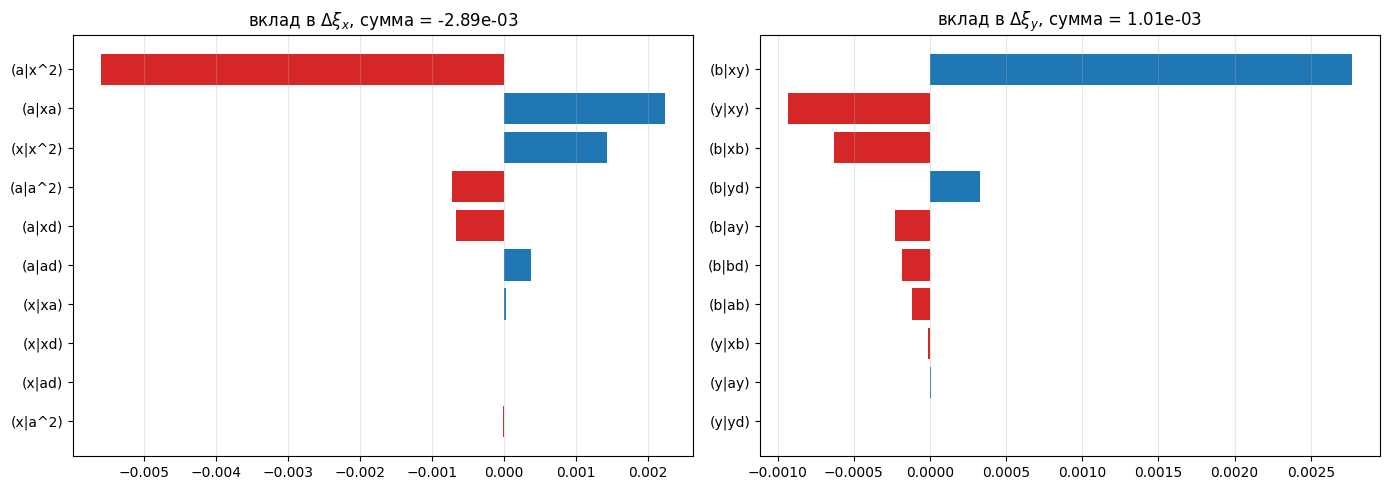

In [16]:
pt = pd.read_csv('single_dipole/output_before_fix/perturb_terms.csv')
t = pt[(pt.gap==0.05)&(pt.pair=='BellSoft-COSYFR3')]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, pl in enumerate(['x','y']):
    d = t[t.plane==pl].copy(); d = d.reindex(d.contrib.abs().sort_values(ascending=False).index).head(10)
    ax[i].barh(d.term, d.contrib, color=['tab:red' if v<0 else 'tab:blue' for v in d.contrib]); ax[i].invert_yaxis()
    ax[i].set_title(r'вклад в $\Delta\xi_%s$, сумма = %.2e' % (pl, t[t.plane==pl].contrib.sum())); ax[i].grid(alpha=.3, axis='x')
plt.tight_layout(); plt.savefig('single_dipole_terms.png', dpi=110); plt.show()

### 9.3. Гипотеза: «секступольный» член $b_2$ прямой границы поля в Bell
В мягком крае Bell (docstring `fringe.jl`) поле в изогнутой системе берётся как $h_0F(s+x\theta(s))$ — прямая граница поля, видимая с искривлённой орбиты ($\theta$ — угол орбиты к прямой). Разложение по $x$ даёт градиент $b_1=h_0F'\theta$ (он обеспечивает FINT и совпадает с COSY линейно) и **секступольноподобный член** $b_2=h_0F''\theta^2$, $H\ni b_2(x^3-3xy^2)/6$. Его интегральная сила на край $K_2L=\int h_0F''\theta^2ds$ (`b2_strength.jl`) $\propto$ GAP. Оценка тонким секступолем на каждом из 32 краёв: $\Delta\xi_x=\frac1{4\pi}\sum K_2L\,\beta_xD$, $\Delta\xi_y=-\frac1{4\pi}\sum K_2L\,\beta_yD$.

**Таблица.** $K_2L$ на один край и вызванный им сдвиг хроматичности в Bell.

In [17]:
b2 = pd.read_csv('single_dipole/output/b2_strength.csv').merge(pd.read_csv('single_dipole/output/b2_estimate.csv'), on='gap')
bell0 = pd.read_csv('BELL/output_before_fix/bell_models.csv'); bell0['gap'] = bell0.gap.round(6)
obs = pd.DataFrame([dict(gap=gp, dxi_x_ring=float(bell0[(bell0.variant=='Soft_Enge_Splitting')&np.isclose(bell0.gap,gp)].xi1x.iloc[0])-cpick('FR3 диполи',gp,'x'),
                         dxi_y_ring=float(bell0[(bell0.variant=='Soft_Enge_Splitting')&np.isclose(bell0.gap,gp)].xi1y.iloc[0])-cpick('FR3 диполи',gp,'y')) for gp in [0.05,0.025,0.0125]])
b2 = b2.merge(obs, on='gap'); b2['x_ratio'] = b2.dxi_x_ring/b2.dxi_x_b2; b2['y_ratio'] = b2.dxi_y_ring/b2.dxi_y_b2; b2

,gap,I,K1L_b1,K2L_b2,W,H1_hb1,K2L_edge,H1_edge,dxi_x_b2,dxi_y_b2,dxi_x_metric,dxi_y_metric,dxi_x_ring,dxi_y_ring,x_ratio,y_ratio
0,0.0500,0.036946,0.000201,-0.000020,0.290001,0.000010,-0.000020,0.000010,-0.002924,0.002024,1.783158e-10,0.001012,-0.002888,0.001007,0.987620,0.497647
1,0.0250,0.018473,0.000100,-0.000010,0.145000,0.000005,-0.000010,0.000005,-0.001462,0.001011,1.810475e-12,0.000506,-0.001454,0.000503,0.994867,0.497209
2,0.0125,0.009236,0.000050,-0.000005,0.072500,0.000003,-0.000005,0.000003,-0.000731,0.000505,5.259012e-12,0.000253,-0.000731,0.000250,0.999456,0.495432


**Рисунок 8.** Наблюдаемая разность Bell − COSY FR3 (кольцо, точки) и оценка от одного члена $b_2$ (линии) в зависимости от GAP.

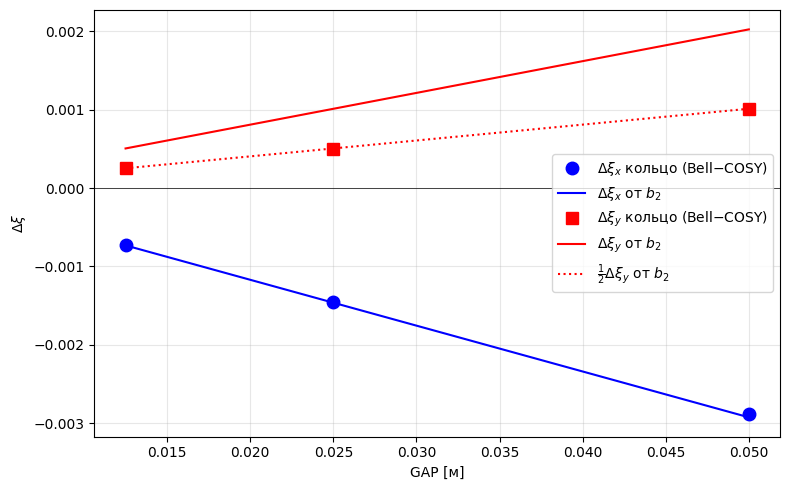

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(b2.gap, b2.dxi_x_ring, 'bo', ms=9, label=r'$\Delta\xi_x$ кольцо (Bell−COSY)'); ax.plot(b2.gap, b2.dxi_x_b2, 'b-', label=r'$\Delta\xi_x$ от $b_2$')
ax.plot(b2.gap, b2.dxi_y_ring, 'rs', ms=9, label=r'$\Delta\xi_y$ кольцо (Bell−COSY)'); ax.plot(b2.gap, b2.dxi_y_b2, 'r-', label=r'$\Delta\xi_y$ от $b_2$'); ax.plot(b2.gap, b2.dxi_y_b2/2, 'r:', label=r'$\frac{1}{2}\Delta\xi_y$ от $b_2$')
ax.axhline(0, color='k', lw=.5); ax.set_xlabel('GAP [м]'); ax.set_ylabel(r'$\Delta\xi$'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig('b2_vs_gap.png', dpi=110); plt.show()

### 9.4. Вывод по диполям
* **Горизонталь: расхождение целиком объясняется членом $b_2$.** Оценка $-2.92\cdot10^{-3}$ против наблюдаемых $-2.89\cdot10^{-3}$ (99 %) при всех GAP; у COSY FR3 в карте BM горизонтальные $(p_x|x^2),(p_x|xa),(x|x^2)$ тождественно нулевые, т.е. в модели COSY для секторного магнита с $e=0$ **нет** секступольноподобного члена от прямой границы поля, а у Bell он есть ($K_2L=-2.0\cdot10^{-5}$ м⁻² на край при 5 см).
* **Вертикаль:** $b_2$ даёт в Bell $+2.0\cdot10^{-3}$, наблюдаемая разность — ровно половина, $+1.0\cdot10^{-3}$. По карте одиночного BM: разность $(p_y|xy)$ Bell − COSY = $-1.96\cdot10^{-5}$, а член $b_2$ даёт $-4.07\cdot10^{-5}$. То есть в COSY есть член $\propto xy$ в вертикальной силе с половинной силой, а горизонтального $x^2$ нет. Поле $b_2(x^3-3xy^2)/6$ в Bell — гармоника прямой системы координат; соотношение «$x^2$‑часть : $xy$‑часть» у COSY другое (вероятно, другая параметризация спада поля вдоль изогнутой орбиты плюс кривизна в уравнениях Максвелла). Разбор по исходнику COSY — в п. 9.5.
* Хроматические ($\propto\delta$) члены и линейная оптика совпадают; квадруполи и секступоли тут не участвуют.

### 9.5. Как это сделано в COSY Infinity (исходник `C:\GIT_REPOS\SCT_2\COSY\src\cosy.fox`, COSY 10.2)
* `MS` (стр. 3502) → `BEND … NT=5`; при `FR 3` вызывается `BENDFF3` (стр. 3325): `NSDP := -4 ; LOFF := 2`, `PPOL(1) := CHIM/R` (однородное поле $B_0$), `PPOL(4) := D` (апертура), `PPOL(7..8) := SIN(-E1N), COS(-E1N)` и `PPOL(9..12)` — **прямые линии** входной и выходной границ поля в декартовой плоскости $(X,Z)$; область интегрирования — дуга $R\varphi$ плюс `LDL := 10*D` с каждой стороны; система координат — **идеальная (жёсткая) окружность** (`LOCSET`), опорная орбита в мягком поле находится отдельно (`SDELEREF`, стр. 2991).
* Поле в средней плоскости: `FIELDXZ` (стр. 2685), ветка `NSDP=-4` (стр. 2709–2714) `BFY := BENDIST(X,Z,1)`; `BENDIST` (стр. 2593) = $B_0\cdot$`ENGES`, где `ENGESIDES` (стр. 2575–2582): `ENGES := ENGE(1,1,IEM,DIS1/D/2)*ENGE(1,2,IEM,DIS2/D/2)`, а `DIST` (стр. 2561) — **декартово расстояние до прямой границы**. То есть $B_y(X,Z)=B_0\,F(d_\perp/2D)$: Энге с масштабом полного зазора $2D$ (подтверждает `Enge(gap=2GAP)` в Bell), коэффициенты — `ENGE`/`FC` (стр. 334–346).
* Вне средней плоскости: `POFF` (стр. 2501) — «off plane terms … satisfying DEL^2 P = 0 in particle optical coordinates», с метрикой `HF := 1+H*DA(IX)`: $\nabla^2$ в изогнутой системе, $\frac{1}{1+hx}\big[\partial_x(1+hx)\partial_x+\partial_s\frac{1}{1+hx}\partial_s\big]$ — Максвелл точно, с кривизной.

**Сравнение с Bell.** Геометрия у обеих программ одна и та же: прямая граница поля, поле в плоскости $h_0F(\text{расстояние до прямой})$; в Bell это $h_0F(s+x\theta)$, т.е. те же $b_1=h_0F'\theta$, $b_2=h_0F''\theta^2$. Разница — в **гамильтониане**: в Bell (`fringe_hamiltonian`, `fringe.jl`) члены поля входят как $b_1(x^2-y^2)/2+b_2(x^3-3xy^2)/6$ **без метрического множителя $(1+hx)$**, хотя $h=h_0F\neq0$ в той же области. В изогнутой системе сила $\propto(1+hx)B_y$, $(1+hx)B_x$, поэтому теряется член $h\,b_1$:
* горизонталь, сила $\propto x^2$: правильно $\tfrac12 b_2 + h b_1$, у Bell $\tfrac12 b_2$;
* вертикаль, сила $\propto xy$: правильно $b_2 + h b_1$, у Bell $b_2$.

Интегрально: $\int\tfrac12 b_2\,ds = -h_0^2\!\int F'F\theta\,ds$ (по частям, $\theta'=h_0F$), а $\int h b_1\,ds = +h_0^2\!\int F F'\theta\,ds$ — **ровно противоположны**. Поэтому в правильной модели горизонтальный секступольный член тождественно сокращается (у COSY $(p_x|x^2),(p_x|xa),(x|x^2)=0$), а вертикальный становится $b_2+hb_1=\tfrac12 b_2$ — **ровно половина** (наблюдаемое отношение 0.497). Численная проверка (`b2_strength.jl`): $H_1=\int hb_1\,ds$ на край против $-K_2L/2$:

In [19]:
b2s = pd.read_csv('single_dipole/output/b2_strength.csv'); be = pd.read_csv('single_dipole/output/b2_estimate.csv')
chk = b2s[['gap','K2L_b2','H1_hb1']].copy(); chk['H1/(-K2L/2)'] = chk.H1_hb1/(-chk.K2L_b2/2)
pred = be.merge(obs, on='gap')
pred['Bell_fixed-COSY_x'] = pred.dxi_x_ring - pred.dxi_x_b2 + pred.dxi_x_metric
pred['Bell_fixed-COSY_y'] = pred.dxi_y_ring - pred.dxi_y_b2 + pred.dxi_y_metric
display(chk); pred[['gap','dxi_x_ring','dxi_y_ring','dxi_x_b2','dxi_y_b2','dxi_x_metric','dxi_y_metric','Bell_fixed-COSY_x','Bell_fixed-COSY_y']]

,gap,K2L_b2,H1_hb1,H1/(-K2L/2)
0,0.0500,-0.000020,0.000010,1.0
1,0.0250,-0.000010,0.000005,1.0
2,0.0125,-0.000005,0.000003,1.0


,gap,dxi_x_ring,dxi_y_ring,dxi_x_b2,dxi_y_b2,dxi_x_metric,dxi_y_metric,Bell_fixed-COSY_x,Bell_fixed-COSY_y
0,0.0500,-0.002888,0.001007,-0.002924,0.002024,1.783158e-10,0.001012,3.619689e-05,-0.000005
1,0.0250,-0.001454,0.000503,-0.001462,0.001011,1.810475e-12,0.000506,7.504438e-06,-0.000003
2,0.0125,-0.000731,0.000250,-0.000731,0.000505,5.259012e-12,0.000253,3.972944e-07,-0.000002


**Таблица.** $H_1/(-K_2L/2)=1.000$ при всех GAP. Прогноз после исправления: Bell − COSY ≈ $+3.6\cdot10^{-5}$ ($\xi_x$) и $-5\cdot10^{-6}$ ($\xi_y$) при 5 см вместо $-2.9\cdot10^{-3}$ / $+1.0\cdot10^{-3}$ (остаток — уровень тонколинзовой оценки).

### 9.6. Итог
* **Физически правильна модель COSY** (декартова прямая граница + решение уравнения Лапласа в изогнутых координатах с метрикой $1+hx$). Модель поля Bell по геометрии та же, но гамильтониан мягкого края не учитывает $(1+hx)$ при градиентном и секступольном членах.
* На вопрос «вертикаль сходится, а горизонталь нет?»: линейная вертикаль (FINT, $Q_y$) совпадает до $10^{-6}$ — её никто не «подгонял», это точный член $b_1$. Нелинейный член неверен в **обеих** плоскостях: в горизонтали Bell даёт лишний секступоль целиком (должен сократиться в ноль), в вертикали — вдвое больший. Поэтому $\Delta\xi_x\approx-2.9\cdot10^{-3}$, $\Delta\xi_y\approx+1.0\cdot10^{-3}$.
* **Что менять в Bell** (`fringe_hamiltonian`): записать вектор‑потенциал поля в изогнутой системе, $A_s=-\int_0^x(1+hx')B_y\,dx'$ с согласованным по Максвеллу (с метрикой) продолжением по $y$; в младшем порядке — добавить к $H$ член $h\,b_1\,(x^3/3 - x y^2/2)$ (даёт силы $h b_1 x^2$ и $h b_1 xy$), либо, что проще, строить $A_s$ как в COSY `POFF` (итерация $P \leftarrow P_0-\iint\frac{1}{1+hx}[\partial_x(1+hx)\partial_x+\partial_s\frac{1}{1+hx}\partial_s]P\,dy\,dy$). Тест: $(p_x|x^2),(p_x|xa),(x|x^2)$ одиночного BM должны стать нулями, $\Delta\xi$ кольца против COSY FR3 — $\lesssim10^{-4}$.

## 10. После исправления ядра Bell
Изменения в `C:\GIT_REPOS\BELL\src\fringe.jl`:
1. `fringe_hamiltonian`: добавлен член $h\,b_1\,(x^3/3 - x y^2/2)$ — метрический множитель $(1+hx)$ силы для градиентного члена мягкого края (раздел 9.5). Он входит в гамильтониан узла/слоя, поэтому одинаково действует в `Splitting`, `Magnus`, `TaylorIntegrate` и для всех профилей.
2. Кэш краевых карт: ключ — `repr(model)` плюс содержимое таблицы для `Tabulated` (раньше таблицы одинаковой длины для разных GAP давали один и тот же результат). Обход «403…409 точек» в `BELL/run.jl` убран, снова 401 точка.

Симплектичность после исправления (`BELL/symp_check.jl`, `BELL/output/symp_check.log`): линейная часть карт краёв $\le1.2\cdot10^{-14}$, якобиан в тестовой точке $\approx9\cdot10^{-14}$, кольцо $\le3\cdot10^{-13}$ — на уровне округления/обрезки 3‑го порядка.

**Таблица.** Bell Soft Enge (Splitting) − COSY FR3 (только диполи), до и после; для $\xi_1$ и $\xi_2$.

In [20]:
rows = []
for gp in GAPS:
    for pl in ['x','y']:
        b0 = bell0[(bell0.variant=='Soft_Enge_Splitting')&np.isclose(bell0.gap,gp)].iloc[0]
        b1_ = bell[(bell.variant=='Soft_Enge_Splitting')&np.isclose(bell.gap,gp)].iloc[0]
        c1 = cpick('FR3 диполи',gp,pl,'xi1'); c2 = cpick('FR3 диполи',gp,pl,'xi2')
        rows.append(dict(GAP=gp, plane=pl, xi1_COSY=c1, dxi1_before=b0['xi1'+pl]-c1, dxi1_after=b1_['xi1'+pl]-c1,
                         xi2_COSY=c2, dxi2_before=b0['xi2'+pl]-c2, dxi2_after=b1_['xi2'+pl]-c2))
ba = pd.DataFrame(rows); ba.to_csv('before_after.csv', index=False); ba

,GAP,plane,xi1_COSY,dxi1_before,dxi1_after,xi2_COSY,dxi2_before,dxi2_after
0,0.05000,x,-1.461498,-0.002888,-0.000003,8.553898,0.007511,0.000201
1,0.05000,y,-1.807670,0.001007,-0.000002,7.316550,0.009764,0.001042
2,0.02500,x,-1.461526,-0.001454,-0.000002,8.554420,0.003827,0.000155
3,0.02500,y,-1.812336,0.000503,-0.000002,7.342792,0.005031,0.000643
4,0.01250,x,-1.461533,-0.000731,-0.000002,8.554551,0.001984,0.000144
5,0.01250,y,-1.814692,0.000250,-0.000002,7.356074,0.002625,0.000424
6,0.00625,x,-1.461535,-0.000367,-0.000002,8.554584,0.001062,0.000141
7,0.00625,y,-1.815876,0.000124,-0.000002,7.362756,0.001412,0.000309


**Рисунок 9.** $|\Delta\xi_1|$ = |Bell − COSY FR3 диполи| до (пунктир) и после (сплошные) исправления, для $x$ и $y$, все гладкие профили и методы Bell после исправления — тонкие линии. Лог. шкалы.

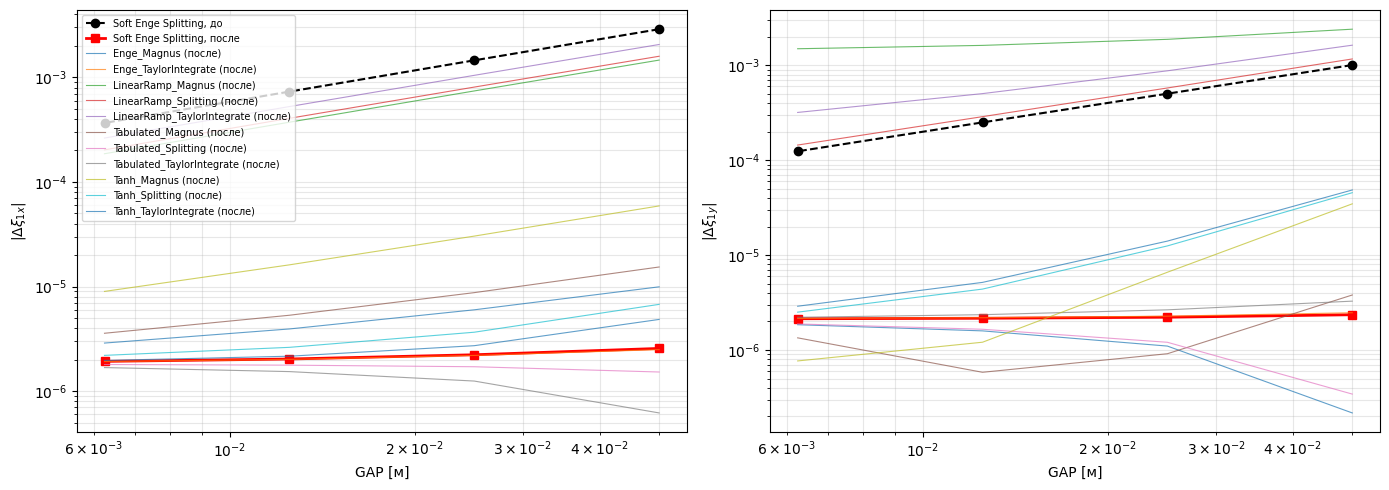

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, pl in enumerate(['x','y']):
    d = ba[ba.plane==pl]
    ax[i].loglog(d.GAP, d.dxi1_before.abs(), 'k--o', label='Soft Enge Splitting, до')
    ax[i].loglog(d.GAP, d.dxi1_after.abs(), 'r-s', lw=2, label='Soft Enge Splitting, после')
    for v, dd in bell[bell.variant.str.startswith('Soft_') & ~bell.variant.str.contains('Quad') & (bell.variant!='Soft_Enge_Splitting')].groupby('variant'):
        dd = dd.sort_values('gap'); ref = np.array([cpick('FR3 диполи',g,pl) for g in dd.gap])
        ax[i].loglog(dd.gap, np.abs(dd['xi1'+pl].values-ref)+1e-12, lw=.8, alpha=.7, label=v[5:]+' (после)')
    ax[i].set_xlabel('GAP [м]'); ax[i].set_ylabel(r'$|\Delta\xi_{1%s}|$' % pl); ax[i].grid(alpha=.3, which='both')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('after_fix_dxi.png', dpi=110); plt.show()

**Таблица.** Ключевые коэффициенты карты одиночного BM (дрейф 0.5 + BM + дрейф 0.5, GAP 5 см): COSY FR3, Bell до и после.

In [22]:
sa = pd.read_csv('single_dipole/output/single_bm_compare.csv'); sb = pd.read_csv('single_dipole/output_before_fix/single_bm_compare.csv')
terms = ['(px|x^2)','(px|xa)','(x|x^2)','(px|xd)','(x|xa)','(py|xy)','(y|xy)','(py|xb)','(py|yd)','(y|b^3)','(py|y^3)']
tt = pd.DataFrame([dict(term=t, COSY_FR3=float(sa[sa.term==t]['cosy_FR3_0.05'].iloc[0]), Bell_before=float(sb[sb.term==t]['bell_Soft_0.05'].iloc[0]),
                        Bell_after=float(sa[sa.term==t]['bell_Soft_0.05'].iloc[0])) for t in terms])
tt['diff_after'] = tt.Bell_after - tt.COSY_FR3; tt

,term,COSY_FR3,Bell_before,Bell_after,diff_after
0,(px|x^2),-2.149177e-11,0.000018,-1.176802e-10,-9.618843e-11
1,(px|xa),-1.398749e-10,0.000116,-7.530329e-10,-6.131580e-10
2,(x|x^2),-5.395273e-03,-0.005333,-5.395271e-03,1.744365e-09
3,(px|xd),5.833572e-10,0.000019,-6.756127e-12,-5.901134e-10
4,(x|xa),3.481449e-01,0.348266,3.481448e-01,-1.330071e-07
5,(py|xy),-2.080033e-03,-0.002100,-2.080032e-03,7.470192e-10
6,(y|xy),-9.632498e-04,-0.001027,-9.632492e-04,5.762335e-10
7,(py|xb),-1.203703e-02,-0.012097,-1.203703e-02,3.399847e-09
8,(py|yd),2.782666e-02,0.027816,2.782665e-02,-9.645274e-09
9,(y|b^3),9.002134e-01,1.534395,1.534398e+00,6.341847e-01


In [23]:
pd.read_csv('single_dipole/output/perturb_summary.csv')

,gap,pair,dxi_x_pert,dxi_y_pert
0,0.0500,BellSoft-COSYFR3,-3.910528e-07,-7.305109e-07
1,0.0500,BellSoft-BellNoEdge,5.284535e-05,4.087380e-01
2,0.0500,COSYFR3-COSYFR0,5.356770e-05,4.087387e-01
3,0.0250,BellSoft-COSYFR3,2.918016e-07,-3.403928e-07
4,0.0250,BellSoft-BellNoEdge,1.335705e-05,4.083664e-01
5,0.0250,COSYFR3-COSYFR0,1.339654e-05,4.083668e-01
6,0.0125,BellSoft-COSYFR3,1.576279e-07,1.084941e-08
7,0.0125,BellSoft-BellNoEdge,3.357295e-06,4.083346e-01
8,0.0125,COSYFR3-COSYFR0,3.530961e-06,4.083345e-01


**Итог исправления.**
* Члены 2‑го порядка одиночного BM теперь совпадают с COSY FR3 до $\sim10^{-9}$ ($(p_x|x^2),(p_x|xa),(p_x|x\delta)\to\sim10^{-10}$, как у COSY); возмущённая оценка Bell − COSY для кольца $\lesssim10^{-6}$.
* В кольце $\Delta\xi_{1x}$: $-2.9\cdot10^{-3}\to\sim-3\cdot10^{-6}$, $\Delta\xi_{1y}$: $+1.0\cdot10^{-3}\to\sim-2\cdot10^{-6}$ при 5 см (таблица выше); $\xi_2$ тоже сблизилась (см. `dxi2_*`).
* Остаются расхождения 3‑го порядка в $y$ ($(y|b^3)$, $(p_y|y^3)$, ∝1/GAP): у Bell гамильтониан края обрезан на степени 4 и член $b_2$ взят без метрики; на линейную хроматичность не влияют, на $\xi_2$ — слабо. Расхождения LinearRamp/Magnus — эффект разрыва $F'$ (метод), а не модели.
* Квадрупольный мягкий край в Bell по‑прежнему отсутствует (раздел 6).

## 11. Хроматичность высших порядков из карты потока Ли (`one_turn_map_flow`, точно, без конечных разностей)
Новый путь Bell (`Bell.LieFlow`): карта каждого элемента $e^{-L:H:}z$ из полного гамильтониана (точный корень, кривизна) до произвольного порядка $N$, одно-оборотная карта $\mathcal M$ порядка $N$ = композиция. Ряд $Q(\delta)$ читает функция ядра `chromaticity_series(lat, N)`:
1. параметрическая замкнутая орбита $u(\delta)$: $\mathcal M_{1..4}(u,0,\delta)=u$ - ньютоновские итерации в DA с постоянной матрицей $(R_0-I)^{-1}$;
2. сдвиг карты на орбиту и линейная часть $R_{ij}(\delta)=\partial\tilde{\mathcal M}_i/\partial z_j|_{z_\perp=0}$ как DA по $\delta$ (точна до $\delta^{N-1}$);
3. $\cos\mu(\delta)=\tfrac12\operatorname{tr}R$ решается ньютоном в DA от ветви $\mu_0\in(0,\pi)$ ($R_{12}>0$), $Q=\mu/2\pi$; $\xi_n=n!\,q_n$, $n\le N-1$.

$\delta=\Delta p/p$, COSY пересчитан из $\delta_K$ как и выше (столбцы `xi*` в `cosy_q_delta.csv`). **Краевые поля в пути потока не реализованы** - сравнение только NoEdge с COSY FR0; углы входа диполей $e_1=e_2=0$ (проверено: 16 BM, ненулевых углов нет), RF-резонатора в структуре нет. Связи $x$-$y$ нет ($R_{1:2,3:4}=0$).
Два варианта решётки Bell: **file** - `magnetic_2_md.bell` как есть (то же, что NoEdge в разд. 2-4); **matched** - те же элементы с точными входными данными COSY: угол BM $=\pi/8$ (в файле 0.3926990753, 8 знаков, $-6.4\cdot10^{-9}$ рад), масса дейтрона 1875.612945 МэВ (COSY `PART`; в Bell 1875.61294257), $k_1=G/B\rho$ с этим $B\rho$.
Программа: `BELL/flow_chrom.jl` → `BELL/output/flow_xi.csv`, `flow_chrom.log` (~25 с).

In [24]:
fx = pd.read_csv('BELL/output/flow_xi.csv')
cq = pd.read_csv('cosy_q_delta.csv'); cf0 = cq[(cq.variant=='FR0')].drop_duplicates('plane').set_index('plane')
NB = 8
T = []
for pl in ['x','y']:
    for n in range(0, 7):
        k = 'q0' if n == 0 else 'xi%d' % n
        c = cf0.loc[pl, k]
        f = fx[(fx.lattice=='file')&(fx.source=='flow')&(fx.N==NB)&(fx.plane==pl)].iloc[0][k]
        m = fx[(fx.lattice=='matched')&(fx.source=='flow')&(fx.N==NB)&(fx.plane==pl)].iloc[0][k]
        T.append(dict(plane=pl, n=n, COSY_FR0=c, Bell_file=f, Bell_matched=m, d_file=f-c, d_matched=m-c, rel_matched=(m-c)/abs(c)))
xt = pd.DataFrame(T); xt.to_csv('flow_xi_vs_cosy.csv', index=False)
pd.set_option('display.float_format', lambda v: '%.10g' % v); xt

,plane,n,COSY_FR0,Bell_file,Bell_matched,d_file,d_matched,rel_matched
0,x,0,0.4617201484,0.4617201386,0.4617201484,-9.73913783e-09,-8.326672685e-16,-1.803402497e-15
1,x,1,-1.461535714,-1.461535736,-1.461535714,-2.181593595e-08,-5.595524044e-14,-3.828523648e-14
2,x,2,8.554595544,8.554595689,8.554595544,1.442951181e-07,4.648725849e-12,5.434185432e-13
3,x,3,-26.87981907,-26.87981768,-26.87981907,1.383878185e-06,-5.72015324e-10,-2.128047524e-11
4,x,4,261.4989518,261.4989626,261.4989519,1.073795988e-05,9.375685295e-08,3.585362476e-10
5,x,5,-4159.750532,-4159.750614,-4159.750551,-8.189197433e-05,-1.925142442e-05,-4.628023789e-09
6,x,6,-21799.56318,-21799.56998,-21799.55848,-0.006804051609,0.00470264359,2.157219184e-07
7,y,0,0.4613373213,0.461337323,0.4613373213,1.771955471e-09,1.498801083e-15,3.248818195e-15
8,y,1,-2.22548493,-2.225484945,-2.22548493,-1.531786786e-08,-1.381117443e-13,-6.20591685e-14
9,y,2,8.103791232,8.103791345,8.103791232,1.128228941e-07,1.592503907e-11,1.965134418e-12


**Таблица 11.1.** $Q_0$ ($n=0$) и $\xi_n=d^nQ/d\delta^n$, $n=1..6$: COSY FR0 (OV 7) против Bell `chromaticity_series(lat, 8)` (точно до $\xi_7$) для решётки *file* и *matched*; `d_*` = Bell − COSY, `rel_matched` = относительная разность. $\xi_6$ у COSY не надёжен (OV 7: старший коэффициент, см. разд. 2).

In [25]:
conv = []
for lt in ['file','matched']:
    for pl in ['x','y']:
        d = fx[(fx.lattice==lt)&(fx.source=='flow')&(fx.plane==pl)].sort_values('N')
        ref = d[d.N==9].iloc[0] if lt=='file' else d[d.N==8].iloc[0]
        for _, r in d.iterrows():
            conv.append(dict(lattice=lt, plane=pl, N=r.N, n_max=r.N-1, xi1=r.xi1, xi3=r.xi3, xi5=r.xi5, seconds=r.seconds))
cv = pd.DataFrame(conv); cv[cv.plane=='x'][['lattice','N','n_max','xi1','xi3','xi5','seconds']]

,lattice,N,n_max,xi1,xi3,xi5,seconds
0,file,3,2,-1.461535736,NaN,NaN,0.0236
1,file,4,3,-1.461535736,-26.87981768,NaN,0.0444
2,file,5,4,-1.461535736,-26.87981768,NaN,0.1687
3,file,6,5,-1.461535736,-26.87981768,-4159.750614,0.3512
4,file,7,6,-1.461535736,-26.87981768,-4159.750614,0.8433
5,file,8,7,-1.461535736,-26.87981768,-4159.750614,2.1907
6,file,9,8,-1.461535736,-26.87981768,-4159.750614,4.8444
14,matched,3,2,-1.461535714,NaN,NaN,0.0346
15,matched,4,3,-1.461535714,-26.87981907,NaN,0.0367
16,matched,5,4,-1.461535714,-26.87981907,NaN,0.0964


**Таблица 11.2.** Независимость от порядка карты: $\xi_1,\xi_3,\xi_5$ ($x$) при $N=3..9$ (пустые - $n>N-1$) и время `one_turn_map_flow` + `chromaticity_series` [с] (Windows, 1 поток). Коэффициенты, доступные при данном $N$, не меняются с ростом $N$ (до $10^{-13}$ отн.) - ряд точен, а не подогнан.

In [26]:
old = []
for lt in ['file','matched']:
    for pl in ['x','y']:
        c = cf0.loc[pl, 'xi1']
        g = lambda s: fx[(fx.lattice==lt)&(fx.source==s)&(fx.plane==pl)].iloc[0]
        fl = fx[(fx.lattice==lt)&(fx.source=='flow')&(fx.N==8)&(fx.plane==pl)].iloc[0]
        old.append(dict(lattice=lt, plane=pl, COSY_xi1=c,
            d_old_FD_dd1e4=g('DF_findiff_dd0.0001').xi1-c, d_DF_exact=g('DF_exact_series').xi1-c, d_flow=fl.xi1-c,
            d_old_FD_xi2=g('DF_findiff_dd0.0001').xi2-cf0.loc[pl,'xi2'], d_DF_exact_xi2=g('DF_exact_series').xi2-cf0.loc[pl,'xi2'], d_flow_xi2=fl.xi2-cf0.loc[pl,'xi2']))
ot = pd.DataFrame(old); ot

,lattice,plane,COSY_xi1,d_old_FD_dd1e4,d_DF_exact,d_flow,d_old_FD_xi2,d_DF_exact_xi2,d_flow_xi2
0,file,x,-1.461535714,-1.824630376e-06,-2.181603609e-08,-2.181593595e-08,0.0001397090564,1.443025983e-07,1.442951181e-07
1,file,y,-2.22548493,-3.025630048e-06,-1.531785809e-08,-1.531786786e-08,0.0003314686829,1.128223044e-07,1.128228941e-07
2,matched,x,-1.461535714,-1.802814776e-06,4.396483178e-14,-5.595524044e-14,0.0001395702785,-3.161915174e-12,4.648725849e-12
3,matched,y,-2.22548493,-3.010312028e-06,-1.580957587e-13,-1.381117443e-13,0.0003313743139,1.723421406e-11,1.592503907e-11


**Таблица 11.3.** Происхождение остатка $\xi_1$ Bell NoEdge − COSY FR0 ($\approx -1.8\cdot10^{-6}$ по $x$, $-3.0\cdot10^{-6}$ по $y$ в разд. 2). Столбцы: старый путь Драгт-Финна, карта порядка 3 + `chromaticity_orders` (центральная разность, шаг $10^{-4}$, как в `run.jl`); та же карта Драгт-Финна, но ряд `chromaticity_series` (точно); путь потока $N=8$. То же для $\xi_2$.

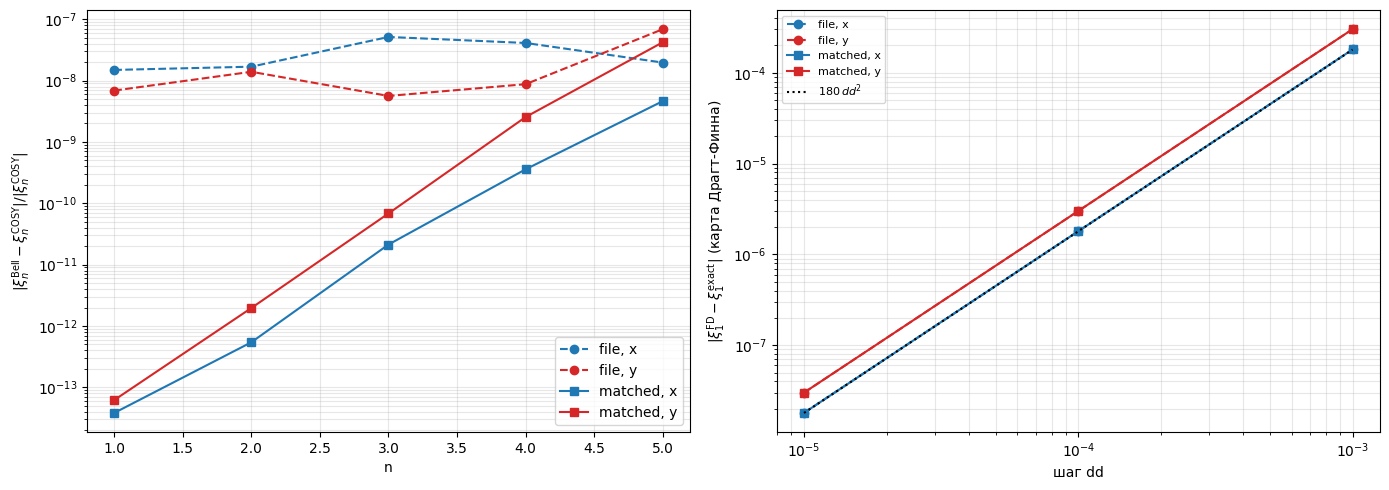

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for lt, mk in [('file','o--'), ('matched','s-')]:
    for pl, c in [('x','tab:blue'), ('y','tab:red')]:
        d = xt[(xt.plane==pl)&(xt.n>=1)&(xt.n<=5)] if lt=='matched' else None
        r = [abs((fx[(fx.lattice==lt)&(fx.source=='flow')&(fx.N==8)&(fx.plane==pl)].iloc[0]['xi%d'%n] - cf0.loc[pl,'xi%d'%n]) / cf0.loc[pl,'xi%d'%n]) for n in range(1,6)]
        ax[0].semilogy(range(1,6), np.maximum(r, 1e-16), mk, color=c, label='%s, %s' % (lt, pl))
ax[0].set_xlabel('n'); ax[0].set_ylabel(r'$|\xi_n^{\rm Bell}-\xi_n^{\rm COSY}|/|\xi_n^{\rm COSY}|$'); ax[0].grid(alpha=.3, which='both'); ax[0].legend()
for lt, mk in [('file','o--'), ('matched','s-')]:
    for pl, c in [('x','tab:blue'), ('y','tab:red')]:
        ex = fx[(fx.lattice==lt)&(fx.source=='DF_exact_series')&(fx.plane==pl)].iloc[0].xi1
        dds = [1e-5, 1e-4, 1e-3]; e = [abs(fx[(fx.lattice==lt)&(fx.source=='DF_findiff_dd%s' % ('1.0e-5' if dd==1e-5 else dd))&(fx.plane==pl)].iloc[0].xi1 - ex) for dd in dds]
        ax[1].loglog(dds, e, mk, color=c, label='%s, %s' % (lt, pl))
dd = np.array([1e-5, 1e-3]); ax[1].loglog(dd, 180*dd**2, 'k:', label=r'$180\,dd^2$')
ax[1].set_xlabel('шаг dd'); ax[1].set_ylabel(r'$|\xi_1^{\rm FD}-\xi_1^{\rm exact}|$ (карта Драгт-Финна)'); ax[1].grid(alpha=.3, which='both'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('flow_xi_vs_cosy.png', dpi=110); plt.show()

**Рисунок 11.** Слева: относительная разность $\xi_n$ Bell (поток Ли, $N=8$) и COSY FR0, $n=1..5$; кружки - решётка *file*, квадраты - *matched* (точные угол, масса, $B\rho$ как в COSY); синий $x$, красный $y$. Справа: ошибка старого чтения `chromaticity_orders` (центральная разность по карте Драгт-Финна порядка 3) относительно точного ряда той же карты в зависимости от шага dd; пунктир $180\,dd^2$ - $q_3^{\rm trunc}dd^2$ с недостоверным кубическим коэффициентом усечённой карты ($\xi_3^{\rm trunc}\approx-1116$ из табл. разд. 4, $q_3\approx-186$).

**Итог разд. 11.**
* **Остаток $\xi_1\sim10^{-6}$ полностью объяснён и исчезает.** Это артефакт конечной разности в `chromaticity_orders`: карта порядка 3 точна только до $\delta^2$ в $Q$, её $q_3$ - мусор усечения ($\approx-186$ против истинного $-4.48$), и центральная разность даёт ошибку $q_3 dd^2\approx1.8\cdot10^{-6}$ при $dd=10^{-4}$ (масштабируется как $dd^2$, рис. 11 справа). Сама карта Драгт-Финна верна: её точный ряд даёт $\xi_1,\xi_2$, совпадающие с путём потока до $10^{-14}$.
* Оставшиеся $\sim2\cdot10^{-8}$ (решётка *file*) - это входные данные: угол BM в `.bell` округлён до 8 знаков и масса дейтрона на $2.4\cdot10^{-6}$ МэВ отличается от COSY. С точными данными (*matched*) $Q_0$ и $\xi_1$ совпадают с COSY до $10^{-13}$-$10^{-14}$, $\xi_2$ до $2\cdot10^{-12}$, $\xi_3$ до $10^{-10}$, $\xi_4$ до $3\cdot10^{-9}$, $\xi_5$ до $4\cdot10^{-8}$ (отн.).
* Рост разности с $n$ при неизменности ряда Bell по $N$ (табл. 11.2) указывает на сторону COSY (пересчёт $\delta_K\to\delta$ и чтение `TP MU` при OV 7); $\xi_6$ COSY ненадёжен.
* Старое $\xi_2$ (вторая разность) отличалось на $1.4\cdot10^{-4}$ (x) и $3\cdot10^{-4}$ (y) по той же причине (через $q_4^{\rm trunc}dd^2$); точный ряд убирает и это.
* Время: $N=8$ (до $\xi_7$) ~2 с, $N=6$ ~0.3 с; старый путь Драгт-Финна (порядок 3, только $\xi_1,\xi_2$) ~0.2 с после компиляции.
* Не сделано: краевые поля (FR3/SoftEdge/HardEdge) в пути потока не реализованы - для них хроматичность высших порядков пока только из старого пути (порядок 3).